In [1]:
from pathlib import Path
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    current = start.resolve()
    while current != current.parent:
        if (current / "src").exists():
            return current
        current = current.parent
    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())
os.chdir(PROJECT_ROOT)

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CWD:", Path.cwd())
print("ARTIFACTS:", ARTIFACTS)

PROJECT_ROOT: .
CWD: .
ARTIFACTS: ./artifacts


In [2]:
SYSTEM_NAME = "kuramoto"
PROFILE_NAME = "profile1"
INTERACTION_TYPE = "energy"
SYSTEM_ORDER = 1

FIT_END_TIME = 0.5
FIGURE_STAGE = "step_6E"

TRAIN_FIT_SPLIT = "train_fit"
TRAIN_FIT_DATASET_NAME = "dataset_train_fit_trial_001"

TRAIN_SPLIT = "train"
TRAIN_DATASET_NAME = "dataset_train_trial_001"

TEST_SPLIT = "test"
TEST_DATASET_NAME = "dataset_test"

NOISE_LEVELS = (0.0, 0.01, 0.03, 0.05, 0.10)
NOISE_TYPE = "multiplicative_uniform"
NOISE_SEED_BASE = 9000

In [ ]:
from ips_learning.analysis.noise_filter_sweep_runner import (
    NoiseFilterSweepConfig,
    NoiseFilterSweepRunner,
)

config_filter = NoiseFilterSweepConfig(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    interaction_type=INTERACTION_TYPE,
    artifact_root=ARTIFACTS,
    system_order=SYSTEM_ORDER,

    train_fit_split=TRAIN_FIT_SPLIT,
    train_fit_dataset_name=TRAIN_FIT_DATASET_NAME,

    train_split=TRAIN_SPLIT,
    train_dataset_name=TRAIN_DATASET_NAME,

    test_split=TEST_SPLIT,
    test_dataset_name=TEST_DATASET_NAME,

    noise_levels=NOISE_LEVELS,
    noise_type=NOISE_TYPE,
    seed_base=NOISE_SEED_BASE,

    train_horizon_end=FIT_END_TIME,

    radial_basis_family="bspline",
    radial_degree=1,
    radial_n_basis=10,

    environment_basis_family="bspline",
    environment_degree=1,
    environment_n_basis_per_dim=10,

    linear_solver_method="lstsq",
    ridge_lambda=1e-8,
    svd_tol=1e-12,

    rollout_method="BDF",
    rollout_rtol=1e-6,
    rollout_atol=1e-6,

    kernel_grid_size=300,
    environment_grid_size=120,

    overwrite=True,
)

runner = NoiseFilterSweepRunner(config_filter)
df_filter = runner.run()

df_filter

In [4]:
filter_eval_dir = ARTIFACTS / SYSTEM_NAME / "evaluations" / "noise_filter_sweep"
filter_metrics_path = filter_eval_dir / "noise_filter_sweep_metrics.csv"

df_filter = pd.read_csv(filter_metrics_path)

df_filter = (
    df_filter
    .sort_values(["noise_level", "preprocessing"])
    .reset_index(drop=True)
)

df_filter

,noise_level,preprocessing,case_name,system_order,environment_variable,E_res,E_phi,E_phi_relative,E_env,E_env_relative,E_recon_train_fit,E_pred_train_same_ic,E_test_preT_unseen_ic,E_test_pred_unseen_ic,cond_A,rollout_failed,failure_message
0,0.00,kalman_filter,trial_000_noise_0p0_kalman_filter,1,position,0.004696,0.016038,0.011109,0.000760,0.020176,0.001552,0.005931,0.001594,0.006924,2653.328898,False,NaN
1,0.00,raw,trial_000_noise_0p0_raw,1,position,0.004720,0.016035,0.011107,0.000753,0.019978,0.001553,0.005931,0.001595,0.006921,2653.328898,False,NaN
2,0.00,sliding_window,trial_000_noise_0p0_sliding_window,1,position,0.040940,0.044779,0.031019,0.001946,0.051655,0.007789,0.031775,0.007818,0.031356,2653.704349,False,NaN
3,0.01,kalman_filter,trial_000_noise_0p01_kalman_filter,1,position,0.047283,0.021489,0.014886,0.010018,0.265958,0.009419,0.022338,0.004188,0.020924,2673.439109,False,NaN
4,0.01,raw,trial_000_noise_0p01_raw,1,position,1.612113,0.072878,0.050483,0.022477,0.596695,0.032103,0.136379,0.013172,0.159682,2626.893020,False,NaN
5,0.01,sliding_window,trial_000_noise_0p01_sliding_window,1,position,0.166027,0.090111,0.062419,0.010471,0.277983,0.018571,0.068161,0.016005,0.068858,2649.930524,False,NaN
6,0.03,kalman_filter,trial_000_noise_0p03_kalman_filter,1,position,0.089585,0.065879,0.045634,0.019016,0.504819,0.022835,0.082171,0.014969,0.103734,2607.751542,False,NaN
7,0.03,raw,trial_000_noise_0p03_raw,1,position,4.908003,0.278816,0.193135,0.064405,1.709739,0.103130,0.235107,0.052244,0.284903,2360.789761,False,NaN
8,0.03,sliding_window,trial_000_noise_0p03_sliding_window,1,position,0.468777,0.147019,0.101840,0.030913,0.820645,0.046471,0.093020,0.030075,0.128400,2610.172350,False,NaN
9,0.05,kalman_filter,trial_000_noise_0p05_kalman_filter,1,position,0.122674,0.073779,0.051107,0.039664,1.052949,0.033730,0.050533,0.012728,0.049305,2522.302510,False,NaN


In [5]:
expected_preprocessing = {"raw", "sliding_window", "kalman_filter"}

assert "preprocessing" in df_filter.columns
assert "case_name" in df_filter.columns

observed_preprocessing = set(df_filter["preprocessing"].unique())

missing_preprocessing = expected_preprocessing - observed_preprocessing
if missing_preprocessing:
    raise ValueError(f"Missing preprocessing cases: {missing_preprocessing}")

expected_rows = len(NOISE_LEVELS) * len(expected_preprocessing)

print("Expected rows:", expected_rows)
print("Observed rows:", len(df_filter))

assert len(df_filter) == expected_rows

print("Noise-filter sweep computation artifacts validated.")

Expected rows: 15
Observed rows: 15
Noise-filter sweep computation artifacts validated.


# Stage 6E 

In [6]:
from ips_learning.visualization.utils import FigureRepository, TableRepository
figure_repo = FigureRepository(root_dir=ARTIFACTS)
table_repo = TableRepository(root_dir=ARTIFACTS)

In [7]:
# # Save clean table and compact paper table

# clean_cols = [
#     "noise_level",
#     "preprocessing",
#     "case_name",
#     "system_order",
#     "environment_variable",
#     "E_res",
#     "E_phi",
#     "E_phi_relative",
#     "E_env",
#     "E_env_relative",
#     "E_recon_train_fit",
#     "E_pred_train_same_ic",
#     "E_test_preT_unseen_ic",
#     "E_test_pred_unseen_ic",
#     "cond_A",
#     "rollout_failed",
#     "failure_message",
# ]

# clean_cols = [c for c in clean_cols if c in df_filter.columns]
# filter_clean_table = df_filter[clean_cols].copy()

# table_repo.save(
#     filter_clean_table,
#     system_name=SYSTEM_NAME,
#     stage_name=FIGURE_STAGE,
#     file_name="noise_filter_sweep_clean_table",
#     index=False,
#     escape=False,
#     float_format="%.4e",
#     caption=f"{SYSTEM_NAME.upper()} noise-filter sweep metrics.",
#     label=f"tab:{SYSTEM_NAME}_noise_filter_sweep",
# )

# paper_cols = [
#     "noise_level",
#     "preprocessing",
#     "E_res",
#     "E_phi",
#     "E_phi_relative",
#     "E_env",
#     "E_env_relative",
#     "E_recon_train_fit",
#     "E_test_pred_unseen_ic",
#     "cond_A",
# ]

# paper_cols = [c for c in paper_cols if c in df_filter.columns]
# filter_paper_table = df_filter[paper_cols].copy()

# table_repo.save(
#     filter_paper_table,
#     system_name=SYSTEM_NAME,
#     stage_name=FIGURE_STAGE,
#     file_name="noise_filter_sweep_core_metrics",
#     index=False,
#     escape=False,
#     float_format="%.4e",
#     caption=f"{SYSTEM_NAME.upper()} core noise-filter sweep metrics.",
#     label=f"tab:{SYSTEM_NAME}_noise_filter_sweep_core",
# )

# filter_paper_table


In [8]:
from ips_learning.visualization.noise_filter_sweep import NoiseFilterSweepVisualizer

viz = NoiseFilterSweepVisualizer(
    system_name=SYSTEM_NAME,
    artifact_root=ARTIFACTS,
    stage_name=FIGURE_STAGE,
)

Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_res_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_phi_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_phi_relative_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_env_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_env_relative_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_recon_train_fit_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_pred_train_same_ic_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_test_pred_unseen_ic_by_preprocessing.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_cond_A_by_preprocessing.png


{'E_res': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_res_by_preprocessing.png'),
 'E_phi': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_phi_by_preprocessing.png'),
 'E_phi_relative': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_phi_relative_by_preprocessing.png'),
 'E_env': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_env_by_preprocessing.png'),
 'E_env_relative': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_env_relative_by_preprocessing.png'),
 'E_recon_train_fit': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_recon_train_fit_by_preprocessing.png'),
 'E_pred_train_same_ic': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_pred_train_same_ic_by_preprocessing.png'),
 'E_test_pred_unseen_ic': PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_E_test_pred_unseen_ic_by_preprocessing.png'),
 'cond_A': PosixPath('

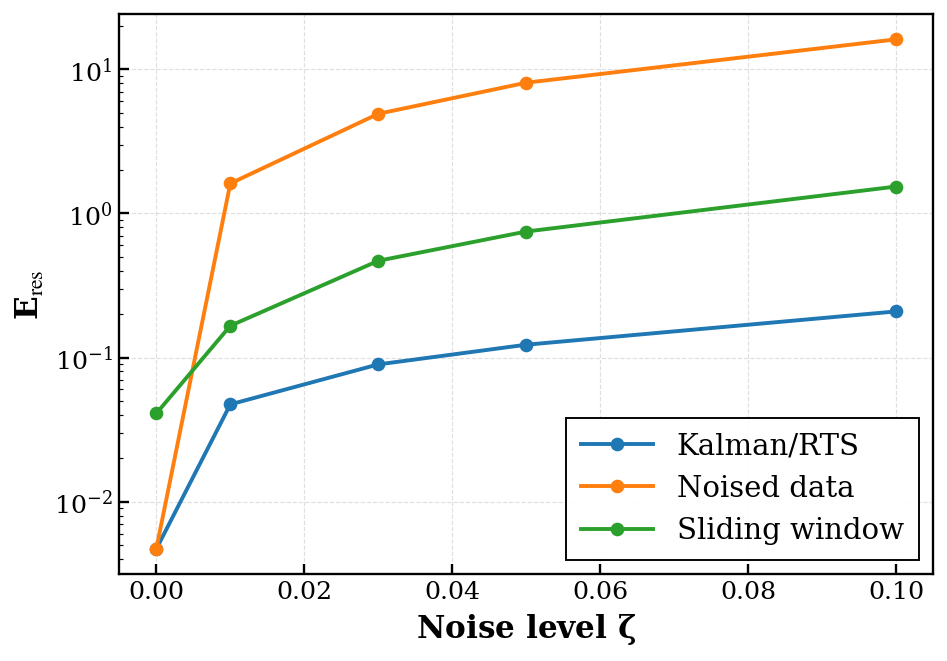

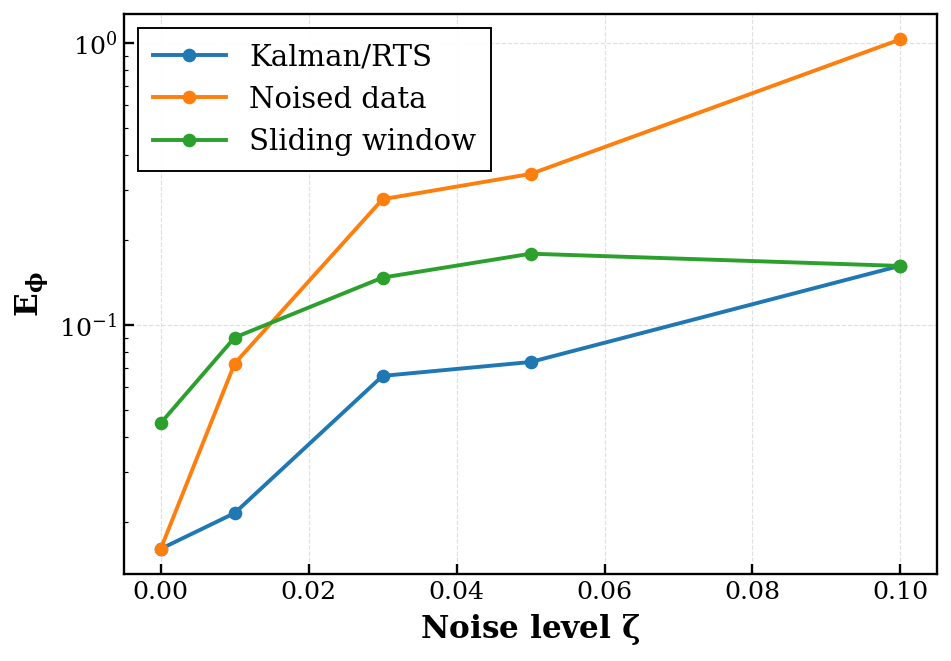

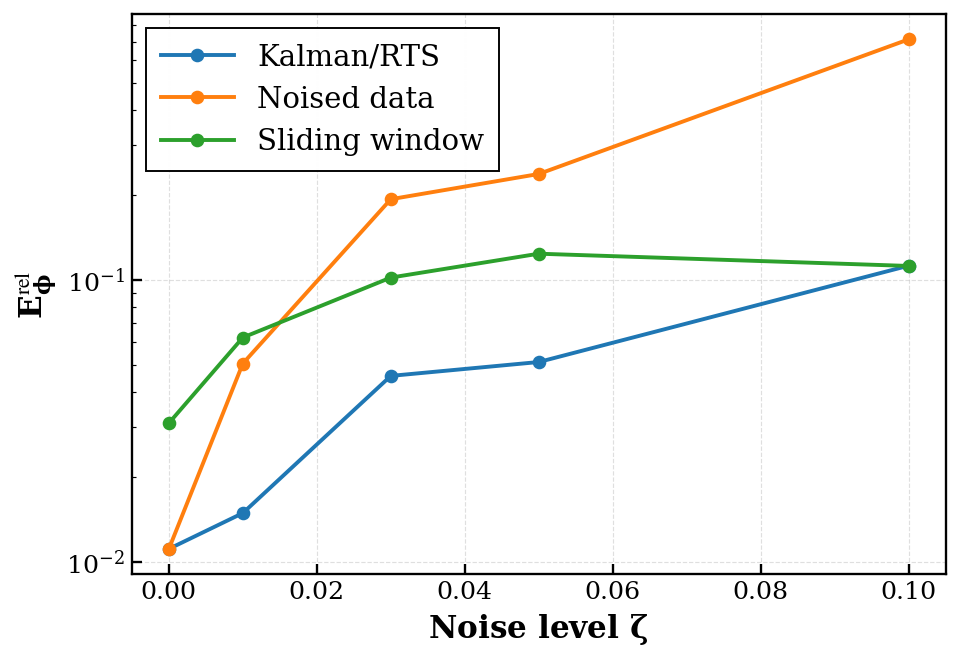

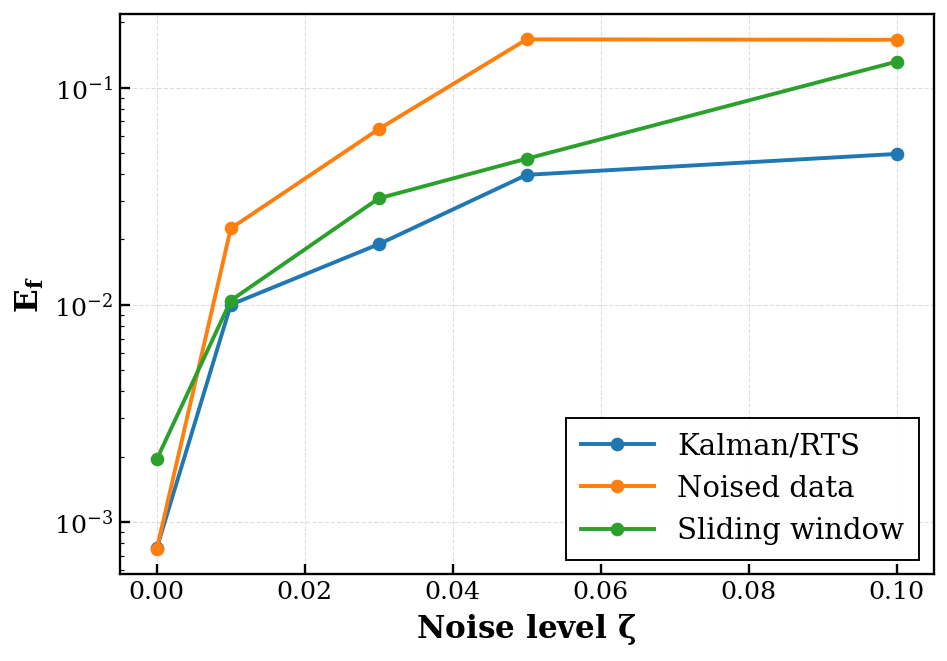

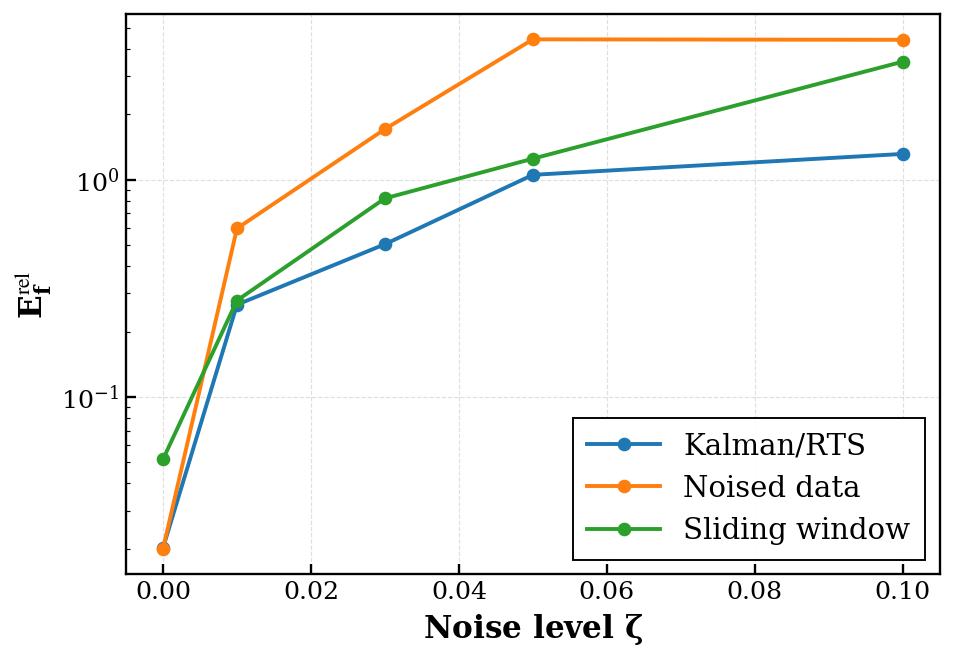

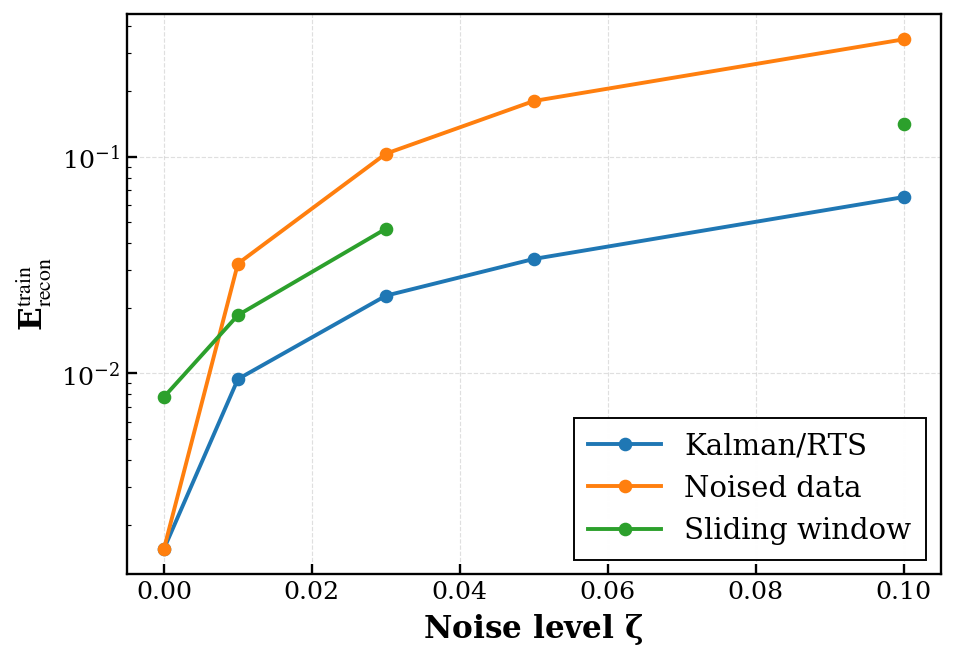

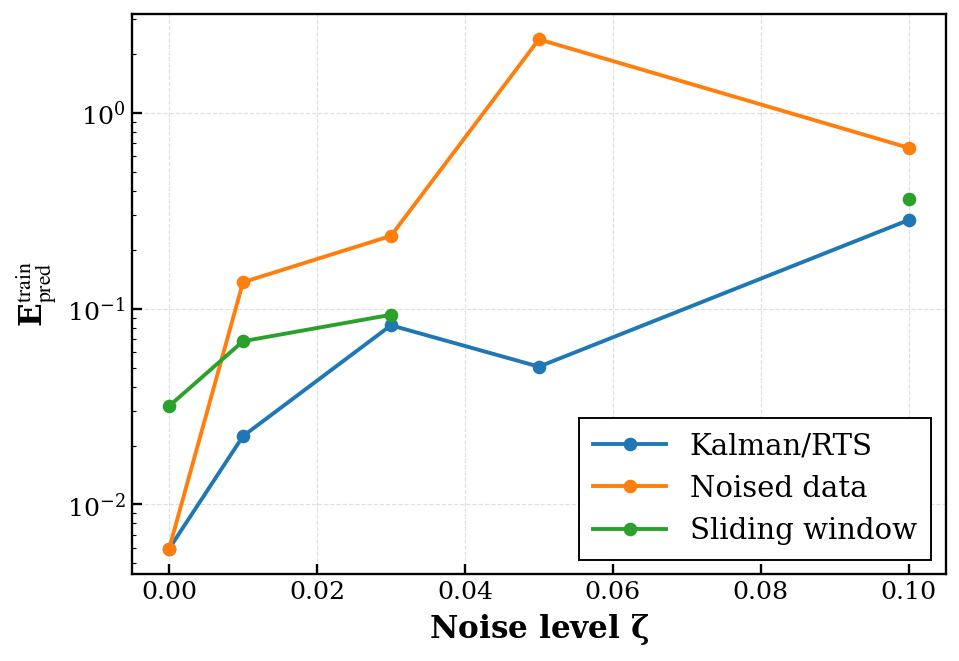

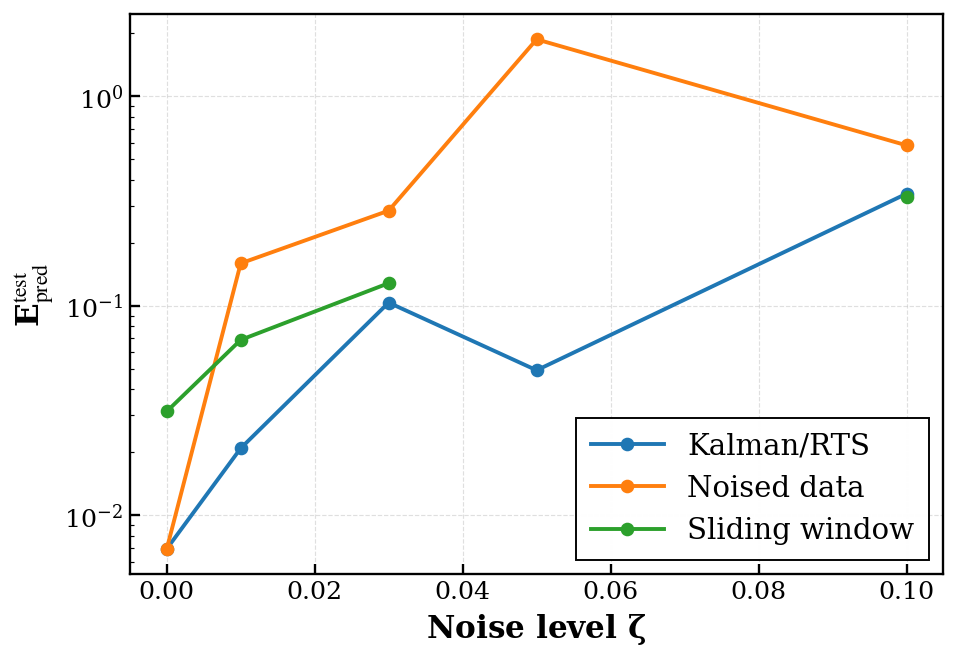

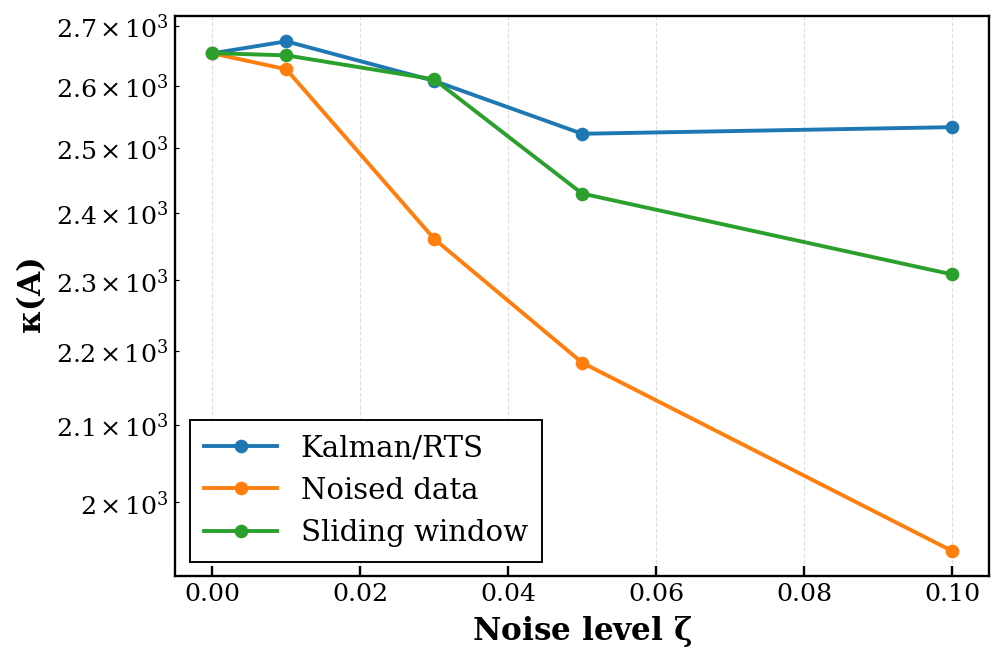

In [9]:
# Metric plots: each plot compares all preprocessing methods across noise levels

metric_specs = [
    ("E_res", r"$E_{\mathrm{res}}$"),
    ("E_phi", r"$E_{\phi}$"),
    ("E_phi_relative", r"$E_{\phi}^{\mathrm{rel}}$"),
    ("E_env", r"$E_f$"),
    ("E_env_relative", r"$E_f^{\mathrm{rel}}$"),
    ("E_recon_train_fit", r"$E_{\mathrm{recon}}^{\mathrm{train}}$"),
    ("E_pred_train_same_ic", r"$E_{\mathrm{pred}}^{\mathrm{train}}$"),
    ("E_test_pred_unseen_ic", r"$E_{\mathrm{pred}}^{\mathrm{test}}$"),
    ("cond_A", r"$\kappa(A)$"),
]

metric_paths = {}

for metric, ylabel in metric_specs:
    if metric not in df_filter.columns:
        print("Skipping missing metric:", metric)
        continue

    values = pd.to_numeric(df_filter[metric], errors="coerce")
    if values.notna().sum() == 0:
        print("Skipping all-NaN metric:", metric)
        continue

    path = viz.plot_metric_vs_noise_by_preprocessing(
        df_filter,
        metric=metric,
        ylabel=ylabel,
        figure_name=f"noise_filter_sweep_{metric}_by_preprocessing",
    )

    metric_paths[metric] = path
    print("Saved:", path)

metric_paths


In [10]:
import numpy as np

from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.bases.repository import BasisRepository
from ips_learning.models.factories import LearnedModelFactory
from ips_learning.systems.registry import (
    true_kernel_from_metadata,
    true_env_from_metadata,
)
from ips_learning.data.dataset_repository import DatasetRepository

In [11]:
PREPROCESSING_ORDER = ["raw", "sliding_window", "kalman_filter"]

def noise_filter_case_name(noise_level: float, preprocessing: str) -> str:
    noise_tag = f"noise_{str(noise_level).replace('.', 'p')}"
    return f"trial_000_{noise_tag}_{preprocessing}"


def load_filter_learned_model(noise_level: float, preprocessing: str, N: int, D: int):
    case_name = noise_filter_case_name(noise_level, preprocessing)

    fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

    fit_result = fit_repo.load_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        fit_case_name=case_name,
    )

    return LearnedModelFactory().build_from_fit_result(
        fit_result=fit_result,
        N=N,
        D=D,
    )

In [12]:
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

train_fit_clean = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

train_full_clean = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

test_clean = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_DATASET_NAME,
)

N = int(train_fit_clean.metadata["N"])
D = int(train_fit_clean.metadata["D"])
SYSTEM_ORDER = int(train_fit_clean.metadata.get("system_order", SYSTEM_ORDER))
ENVIRONMENT_VARIABLE = "position" if SYSTEM_ORDER == 1 else "velocity"

true_phi = true_kernel_from_metadata(train_fit_clean.metadata)

try:
    true_f = true_env_from_metadata(train_fit_clean.metadata)
except Exception:
    true_f = None

print("N, D:", N, D)
print("system_order:", SYSTEM_ORDER)
print("environment_variable:", ENVIRONMENT_VARIABLE)
print("has true_env:", true_f is not None)

N, D: 10 1
system_order: 1
environment_variable: position
has true_env: True


In [13]:
# dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

# train_fit_clean = dataset_repo.load(
#     system_name=SYSTEM_NAME,
#     split=TRAIN_FIT_SPLIT,
#     dataset_name=TRAIN_FIT_DATASET_NAME,
# )

# N = int(train_fit_clean.metadata["N"])
# D = int(train_fit_clean.metadata["D"])
# SYSTEM_ORDER = int(train_fit_clean.metadata.get("system_order", SYSTEM_ORDER))

# ENVIRONMENT_VARIABLE = "position" if SYSTEM_ORDER == 1 else "velocity"

# true_phi = true_kernel_from_metadata(train_fit_clean.metadata)
# true_f = true_env_from_metadata(train_fit_clean.metadata)

# learned_models = {
#     float(zeta): load_noise_learned_model(float(zeta), N=N, D=D)
#     for zeta in df_noise["noise_level"].to_numpy()
# }

In [ ]:
# Build the same fixed clean empirical measure used by
# NoiseFilterSweepRunner for function-error weighting and visualization.

from ips_learning.features.feature_builder import FeatureBuilder
from ips_learning.statistics.density import build_empirical_error_density

features_clean = FeatureBuilder().build(train_fit_clean)
basis_clean = runner.basis_builder.build(features_clean)

empirical_density_clean = build_empirical_error_density(
    features=features_clean,
    localization_metadata=basis_clean.localization_metadata,
    kernel_grid_size=config_filter.kernel_grid_size,
    environment_grid_size=config_filter.environment_grid_size,
)

r_grid = empirical_density_clean.r_grid
pdf_r_ref = empirical_density_clean.kernel_weights

z1_grid = empirical_density_clean.z1_grid
z2_grid = empirical_density_clean.z2_grid

if z2_grid is None:
    pdf_z_ref = empirical_density_clean.environment_weights
else:
    pdf_z_ref = empirical_density_clean.environment_weights.reshape(
        len(z1_grid),
        len(z2_grid),
    )

print("r_grid:", r_grid.shape)
print("pdf_r_ref:", pdf_r_ref.shape)
print("z1_grid:", z1_grid.shape)
print("z2_grid:", None if z2_grid is None else z2_grid.shape)
print("pdf_z_ref:", pdf_z_ref.shape)


Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p0.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p0.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p01.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p01.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p03.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p03.png
Skipping sliding_window at ζ=0.05: rollout failed. Learned-system rollout failed: Required step size is less than spacing between numbers.
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p05.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p05.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p1.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p1.png


{(0.0,
  'phi'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p0.png'),
 (0.0,
  'env'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p0.png'),
 (0.01,
  'phi'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p01.png'),
 (0.01,
  'env'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p01.png'),
 (0.03,
  'phi'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p03.png'),
 (0.03,
  'env'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p03.png'),
 (0.05,
  'phi'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p05.png'),
 (0.05,
  'env'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_env_curve_zeta_0p05.png'),
 (0.1,
  'phi'): PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_phi_zeta_0p1.png'),
 (0.1,
  'env'): PosixPath('

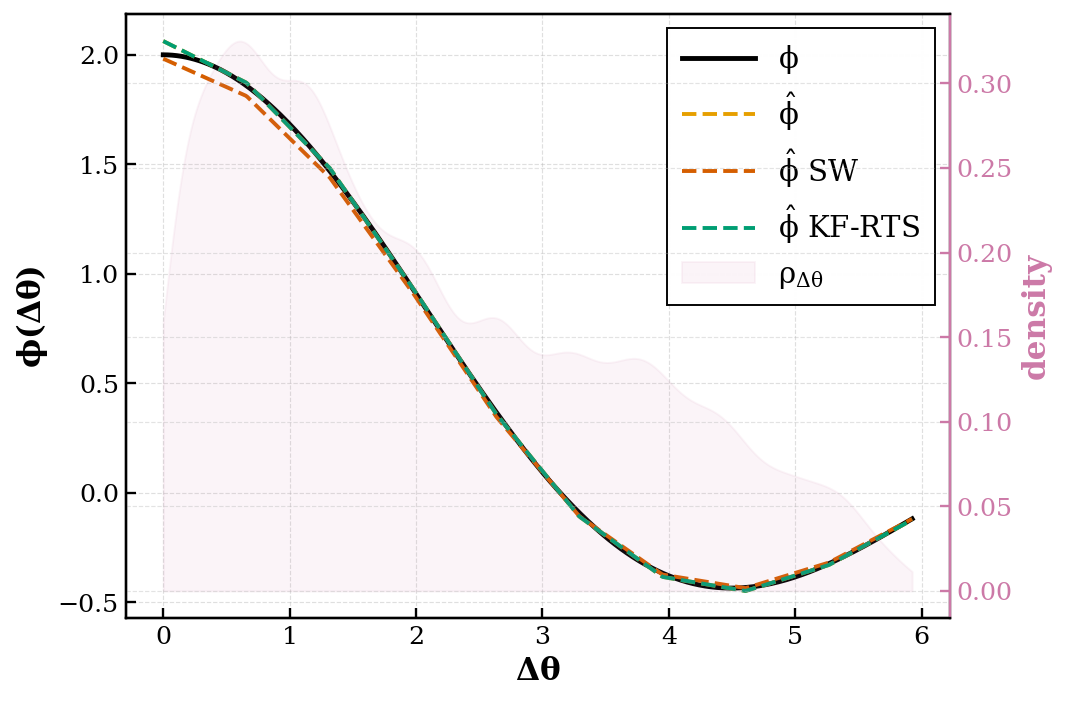

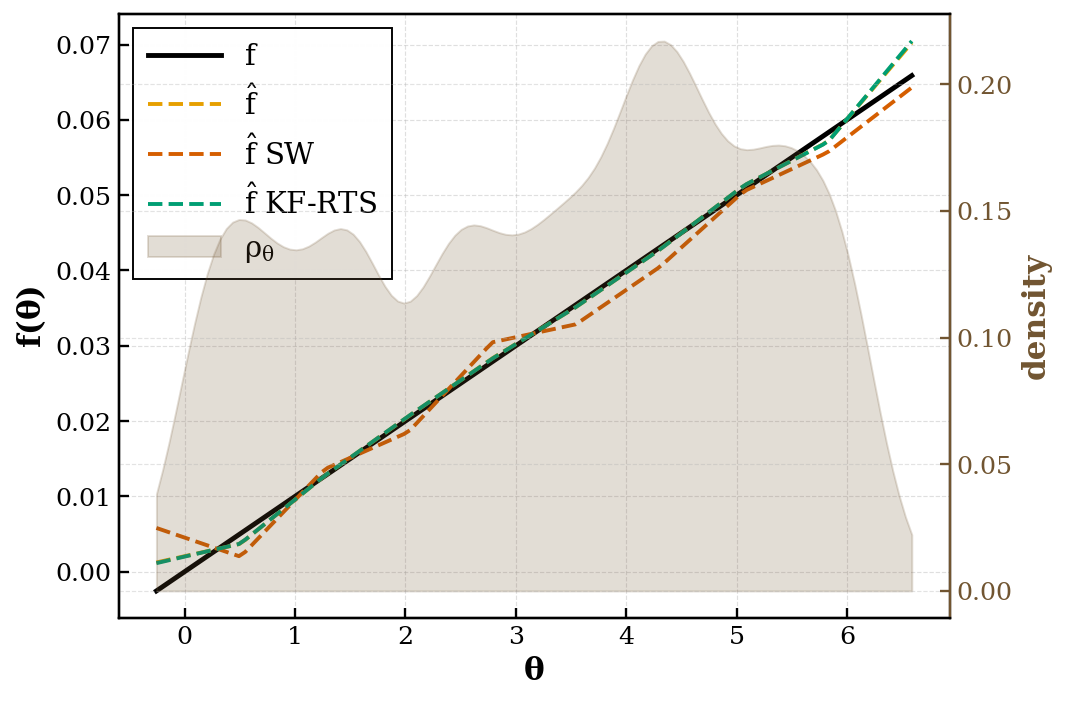

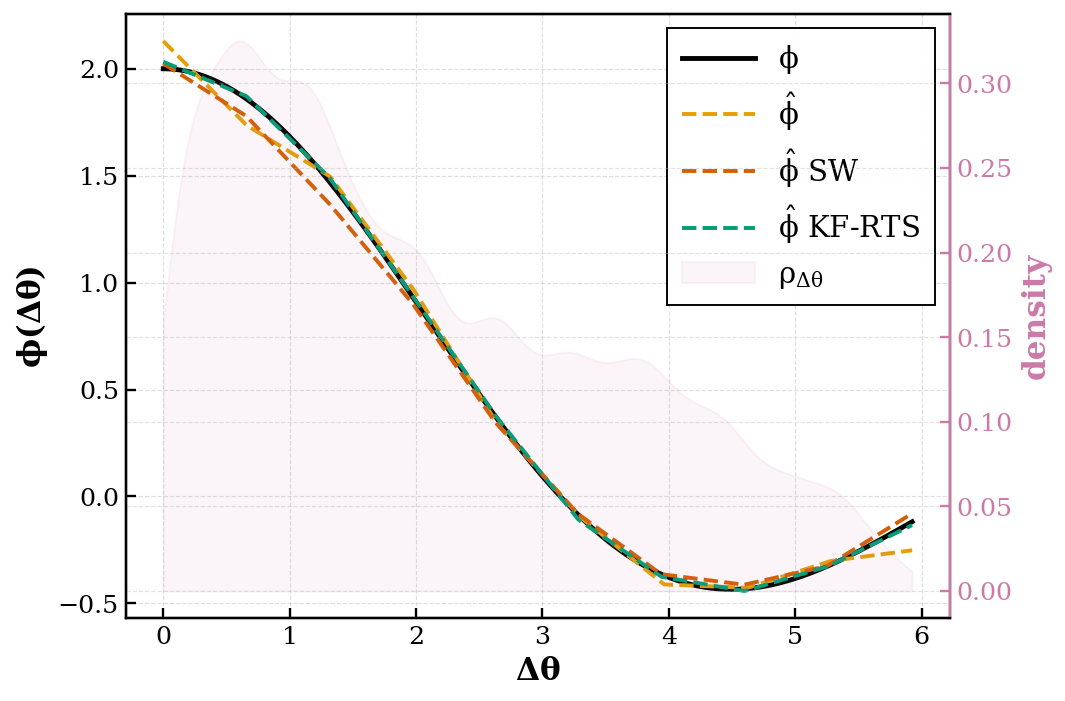

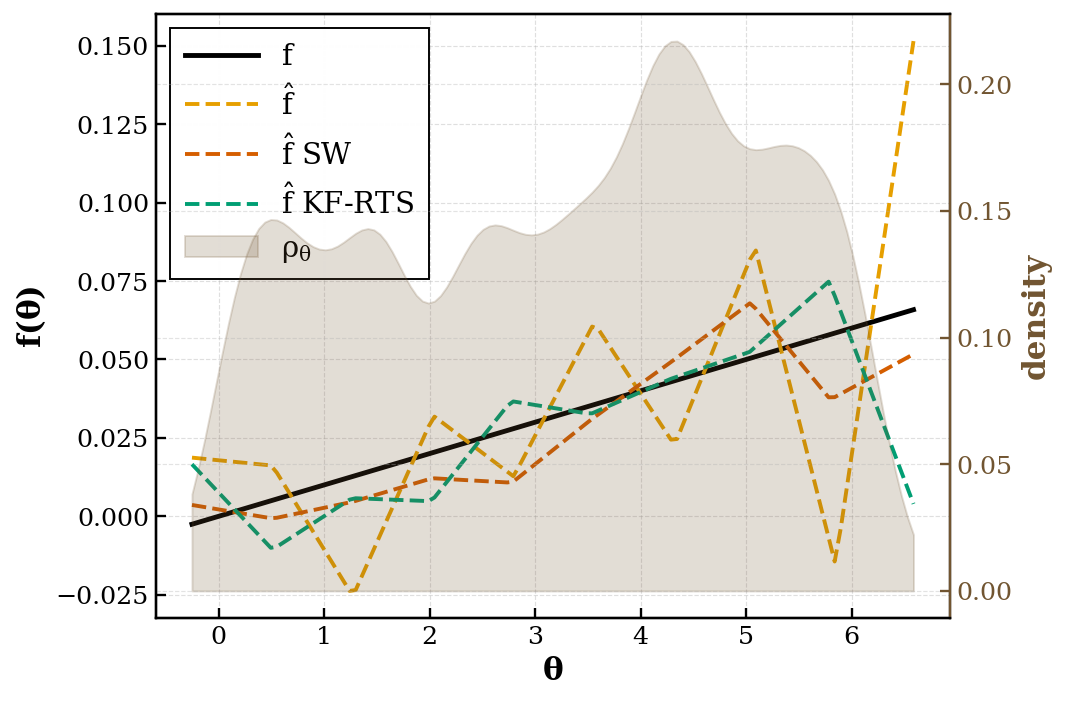

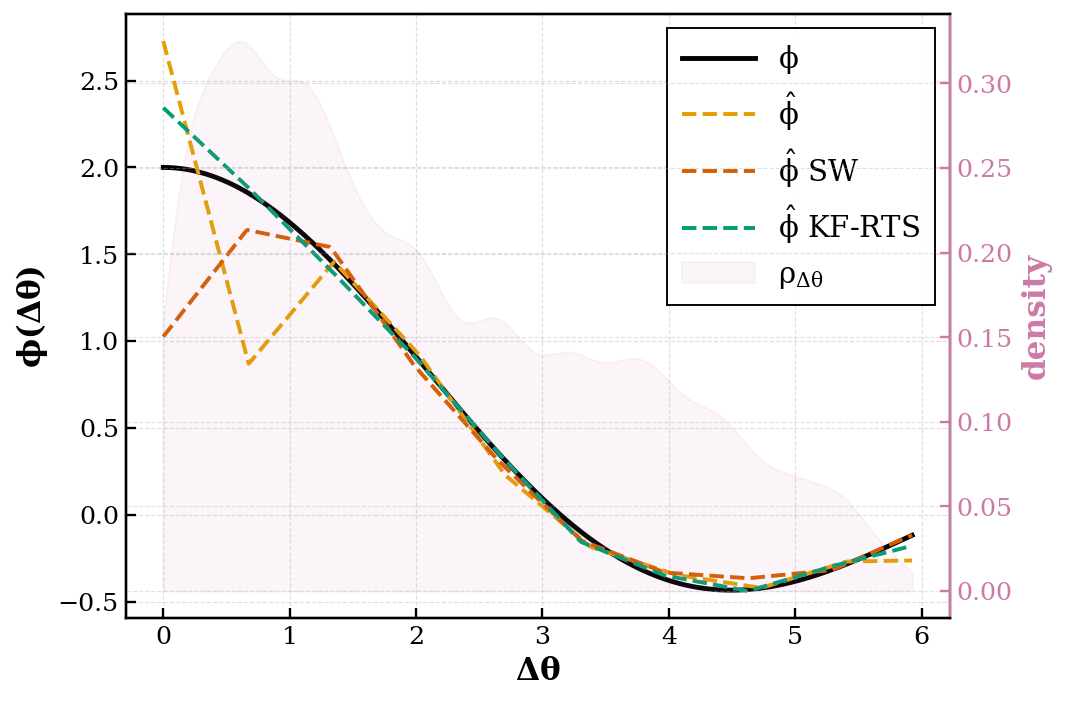

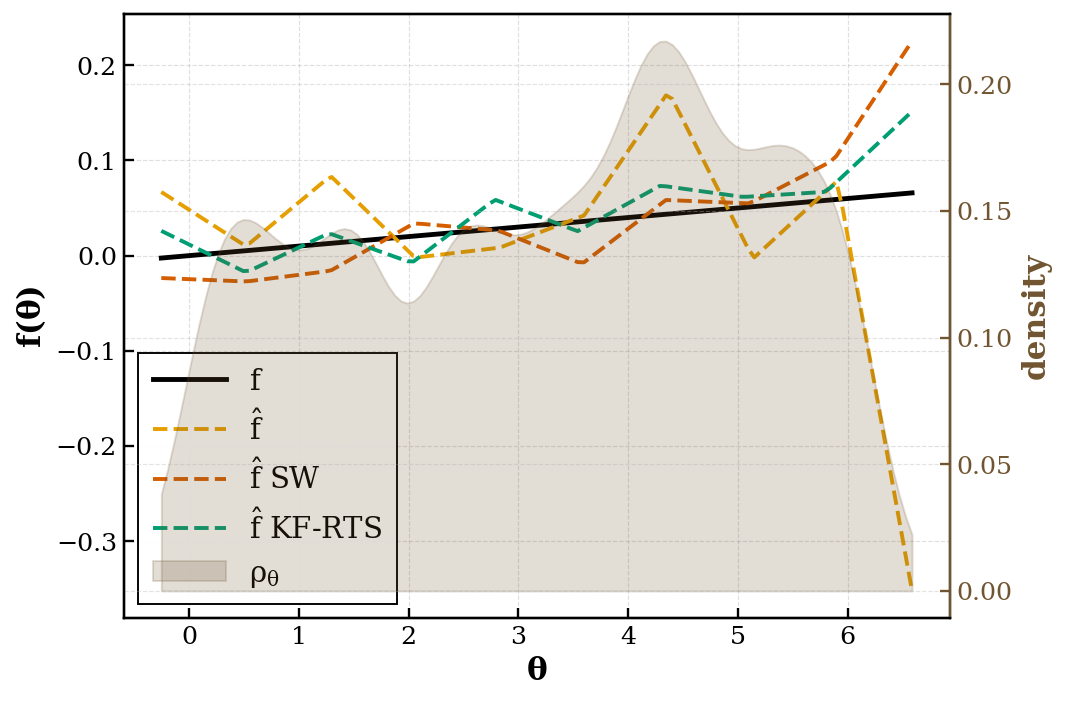

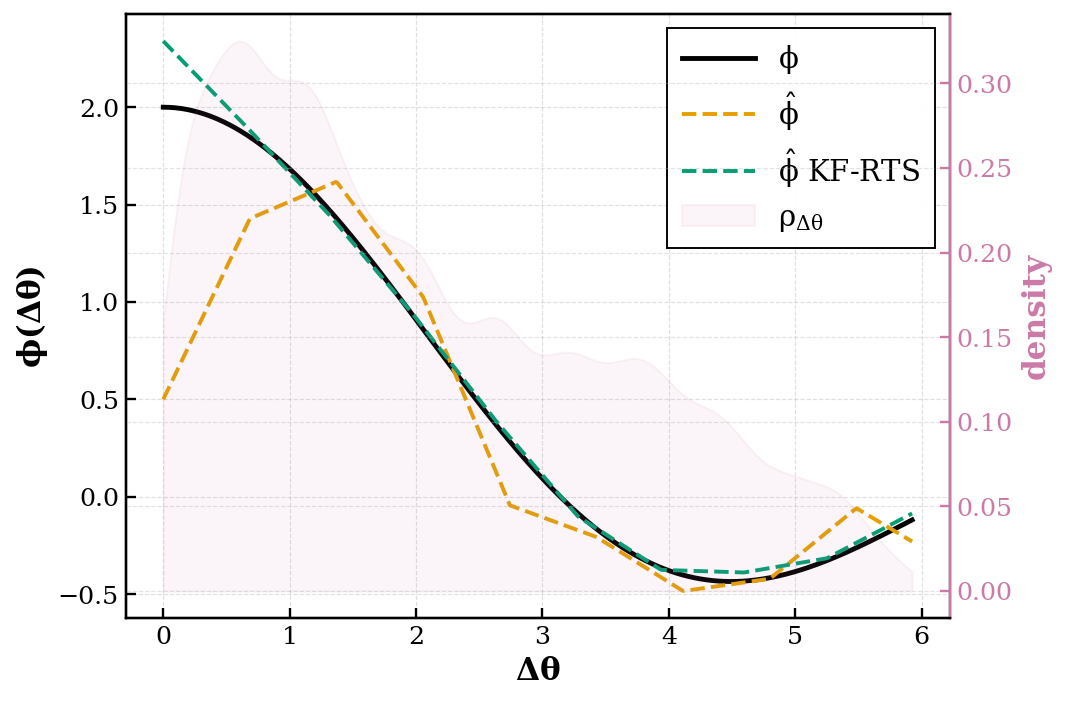

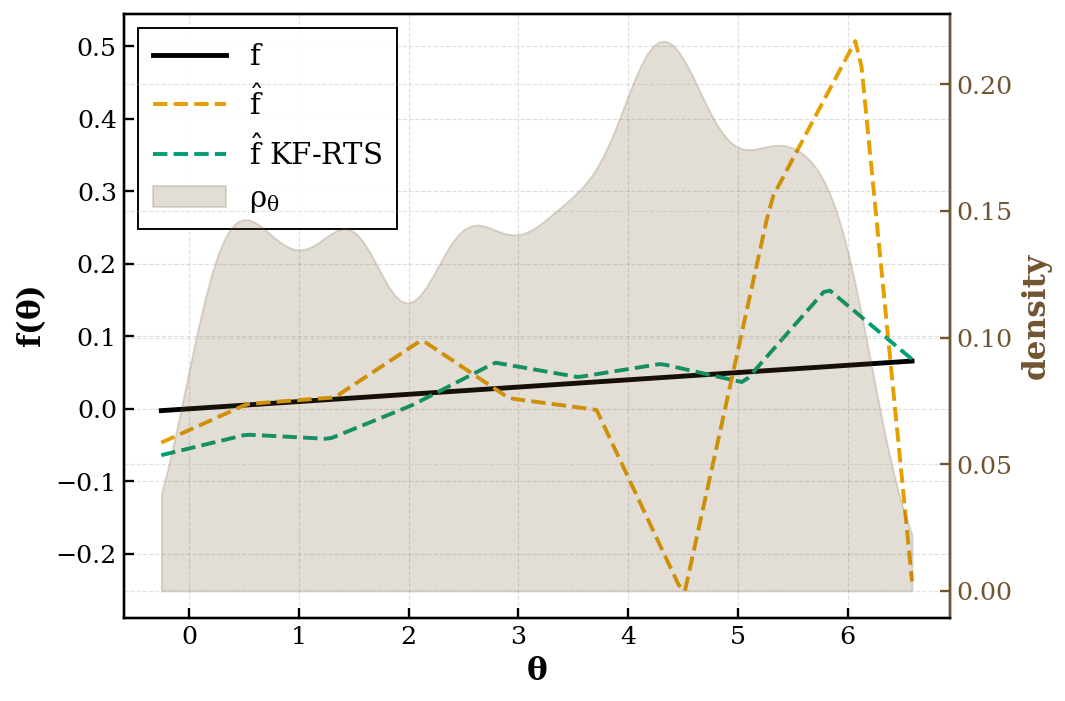

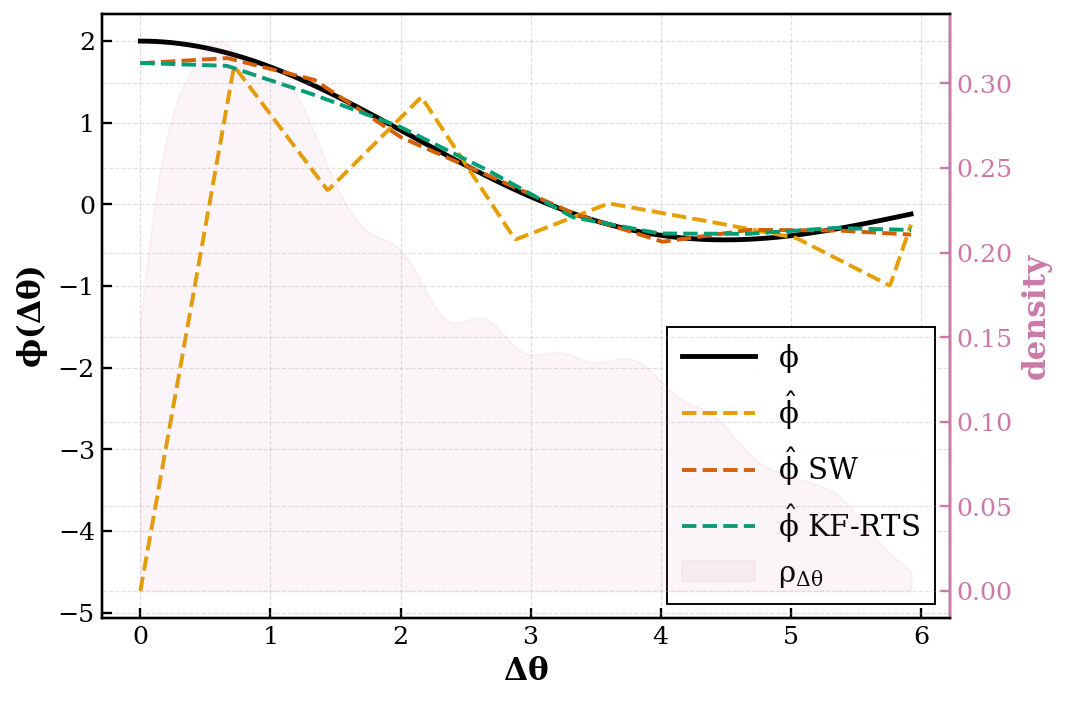

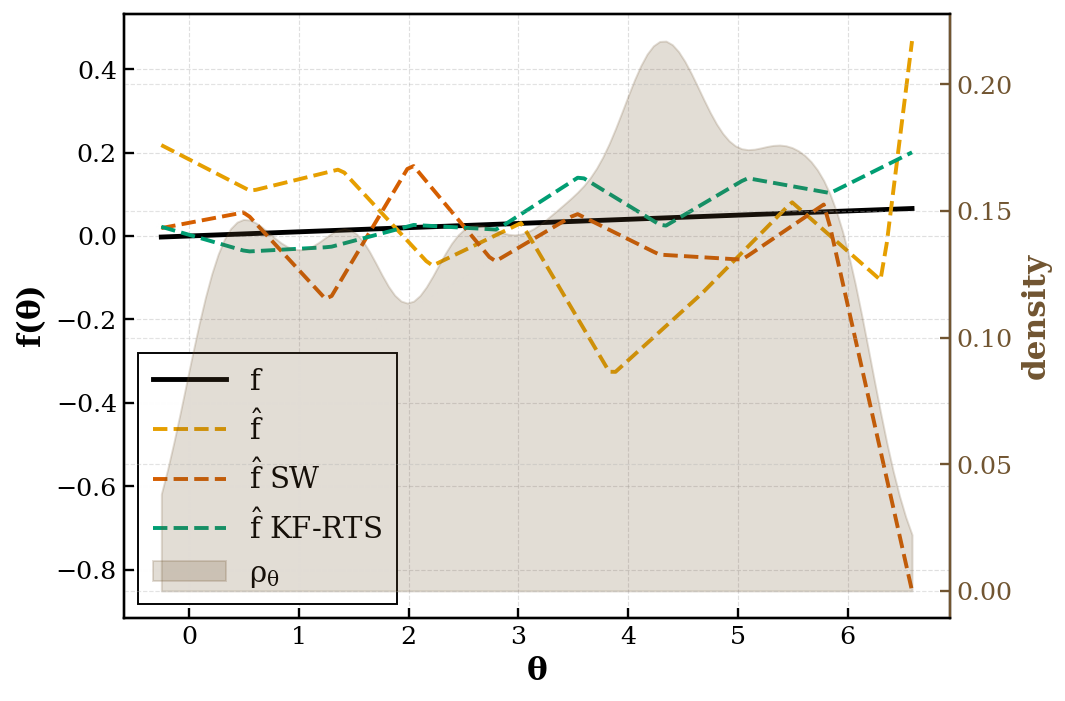

In [15]:
# Learned function comparison: one figure per noise level, all preprocessing methods in one plot

TARGET_NOISE_LEVELS = tuple(float(z) for z in sorted(df_filter["noise_level"].unique()))

function_paths = {}

for target_noise_level in TARGET_NOISE_LEVELS:
    learned_models = {}

    for preprocessing in PREPROCESSING_ORDER:
        row = df_filter[
            (np.isclose(df_filter["noise_level"], target_noise_level))
            & (df_filter["preprocessing"] == preprocessing)
        ]

        if row.empty:
            print(f"Skipping {preprocessing} at ζ={target_noise_level}: no metrics row.")
            continue

        if bool(row.iloc[0].get("rollout_failed", False)):
            print(
                f"Skipping {preprocessing} at ζ={target_noise_level}: rollout failed. "
                f"{row.iloc[0].get('failure_message', '')}"
            )
            continue

        learned_models[preprocessing] = load_filter_learned_model(
            noise_level=target_noise_level,
            preprocessing=preprocessing,
            N=N,
            D=D,
        )

    if not learned_models:
        print(f"No successful learned models for ζ={target_noise_level}.")
        continue

    path_phi = viz.plot_phi_vs_r_filter_panel(
        r_grid=r_grid,
        true_phi=true_phi,
        learned_phi_by_preprocessing={
            preprocessing: model.learned_kernel
            for preprocessing, model in learned_models.items()
        },
        noise_level=target_noise_level,
        dist_density_ref=pdf_r_ref,
        labels={
            "xlabel": r"$\Delta \theta$" if SYSTEM_NAME == "kuramoto" else r"$r$",
            "ylabel_left": r"$\phi(\Delta \theta)$" if SYSTEM_NAME == "kuramoto" else r"$\phi(r)$",
            "density": r"$\rho_{\Delta \theta}$",
            "ylabel_right": "density",
        },
    )

    function_paths[(target_noise_level, "phi")] = path_phi
    print("Saved:", path_phi)

    if true_f is not None:
        if D == 1:
            path_env = viz.plot_env_curves_by_filter(
                z_grid=z1_grid,
                true_env=true_f,
                learned_env_by_preprocessing={
                    preprocessing: model.learned_environment
                    for preprocessing, model in learned_models.items()
                },
                noise_level=target_noise_level,
                env_density_ref=np.asarray(pdf_z_ref).reshape(-1),
                labels={
                    "xlabel": r"$\theta$" if SYSTEM_NAME == "kuramoto" else r"$z$",
                    "ylabel_left": r"$f(\theta)$" if SYSTEM_NAME == "kuramoto" else r"$f(z)$",
                    "density": r"$\rho_{\theta}$",
                    "ylabel_right": "density",
                },
            )
        else:
            path_env = viz.plot_env_surfaces_by_filter(
                v1_grid=z1_grid,
                v2_grid=z2_grid,
                true_env=true_f,
                learned_env_by_preprocessing={
                    preprocessing: model.learned_environment
                    for preprocessing, model in learned_models.items()
                },
                noise_level=target_noise_level,
                vel_density_ref=pdf_z_ref,
            )

        function_paths[(target_noise_level, "env")] = path_env
        print("Saved:", path_env)

function_paths


In [ ]:
# Reconstruct noisy/filtered training observations for trajectory visualization

from ips_learning.rollout.repository import RolloutRepository
from ips_learning.data.sliding_window_noise import SlidingWindowNoise
from ips_learning.data.kalman_filter_noise import KalmanFilterNoise

rollout_repo = RolloutRepository(root_dir=ARTIFACTS / "rollouts")


def make_noise_variants(noise_level: float):
    sliding_model = SlidingWindowNoise(
        noise_level=noise_level,
        seed=NOISE_SEED_BASE + int(noise_level * 1000),
        noise_type=NOISE_TYPE,
    )
    train_fit_sliding = sliding_model.perturb(train_fit_clean)

    kalman_model = KalmanFilterNoise(
        noise_level=noise_level,
        seed=NOISE_SEED_BASE + int(noise_level * 1000),
        noise_type=NOISE_TYPE,
    )
    train_fit_raw, train_fit_kalman = kalman_model.perturb(train_fit_clean)

    return {
        "raw": train_fit_raw,
        "sliding_window": train_fit_sliding,
        "kalman_filter": train_fit_kalman,
    }


def load_train_prediction_artifact(noise_level: float, preprocessing: str):
    case_name = noise_filter_case_name(noise_level, preprocessing)

    return rollout_repo.load_case(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        case_name=case_name,
        scenario="noise_same_ic_prediction",
        rollout_name=f"{case_name}_noise_same_ic_prediction",
    )


Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p0.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p01.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p03.png
Skipping sliding_window at ζ=0.05: rollout failed. Learned-system rollout failed: Required step size is less than spacing between numbers.
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p05.png
Saved: ./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p1.png


{0.0: PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p0.png'),
 0.01: PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p01.png'),
 0.03: PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p03.png'),
 0.05: PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p05.png'),
 0.1: PosixPath('./artifacts/kuramoto/figures/step_6E/noise_filter_sweep_seen_ic_all_preprocessing_zeta_0p1.png')}

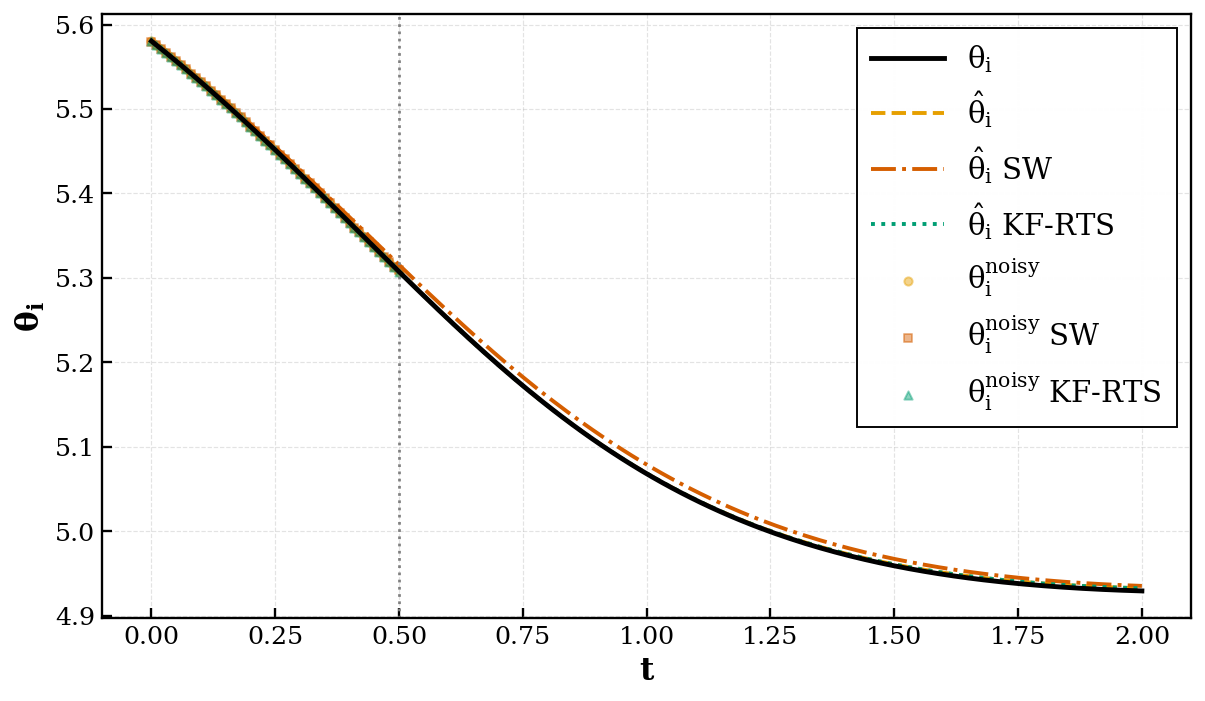

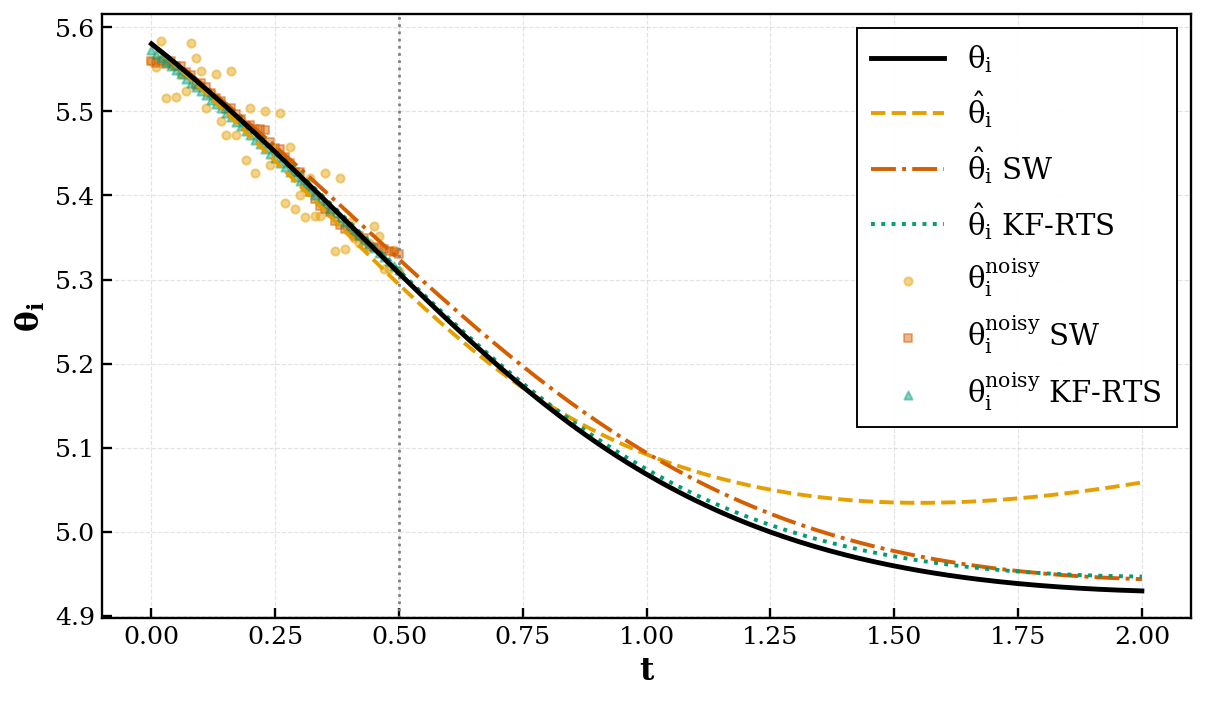

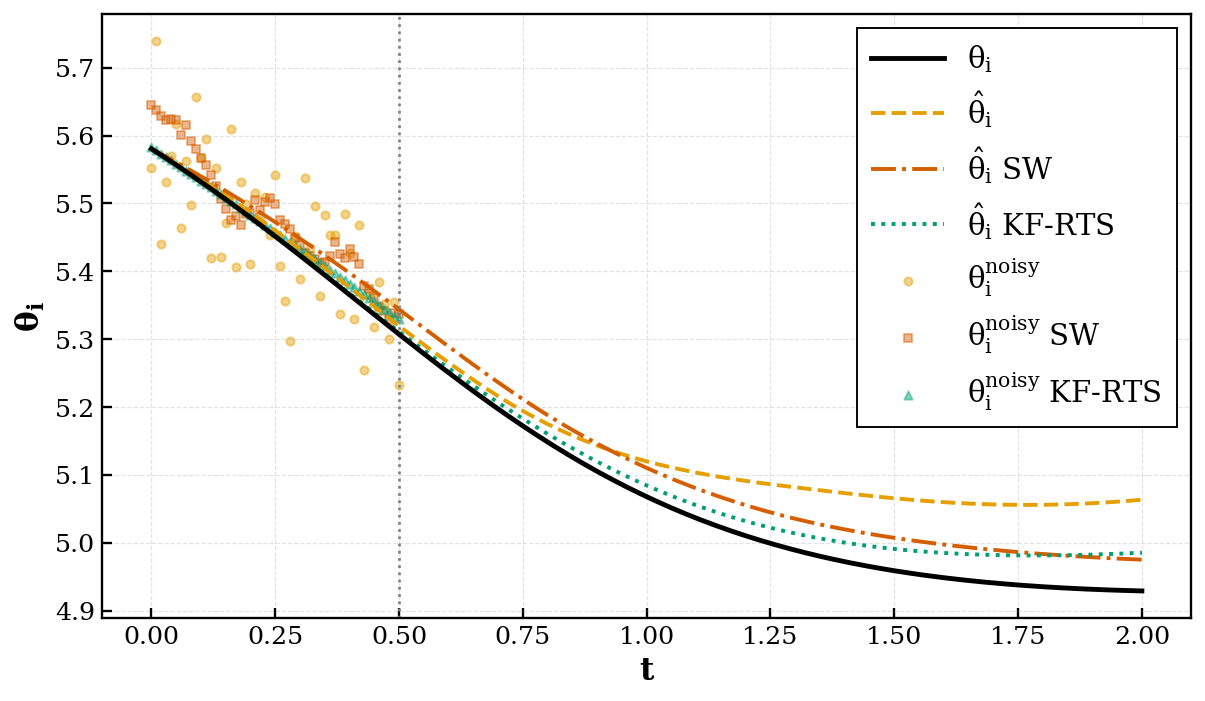

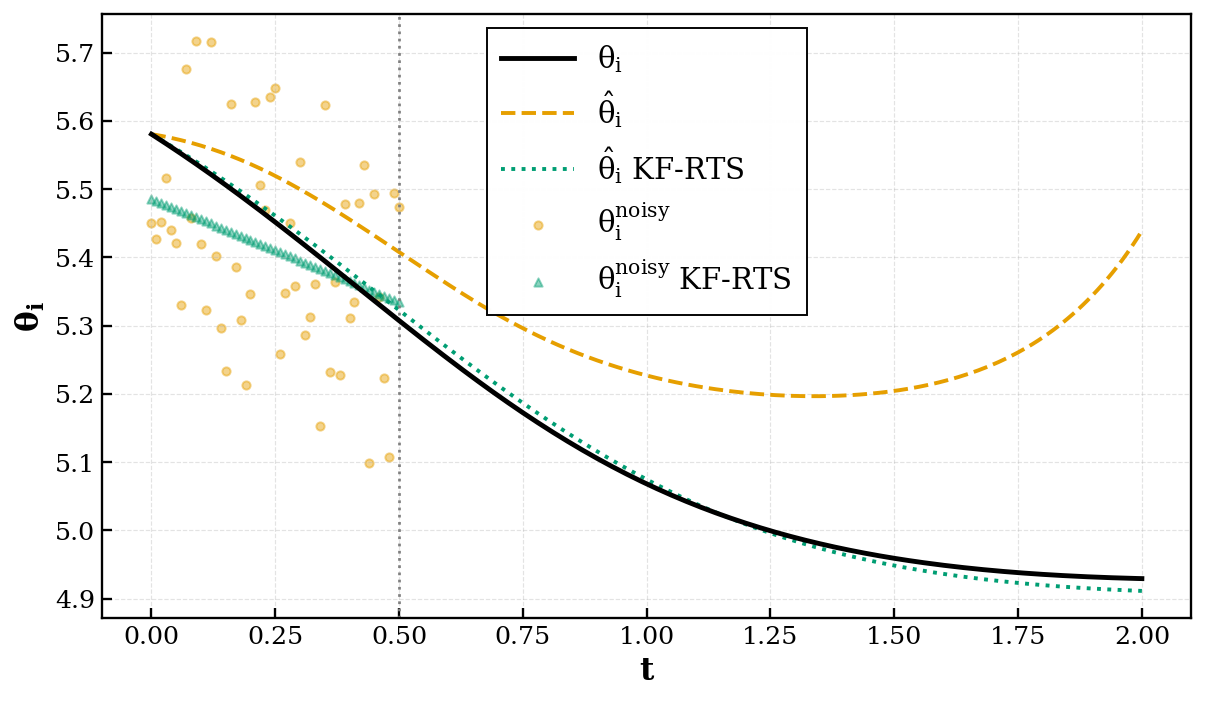

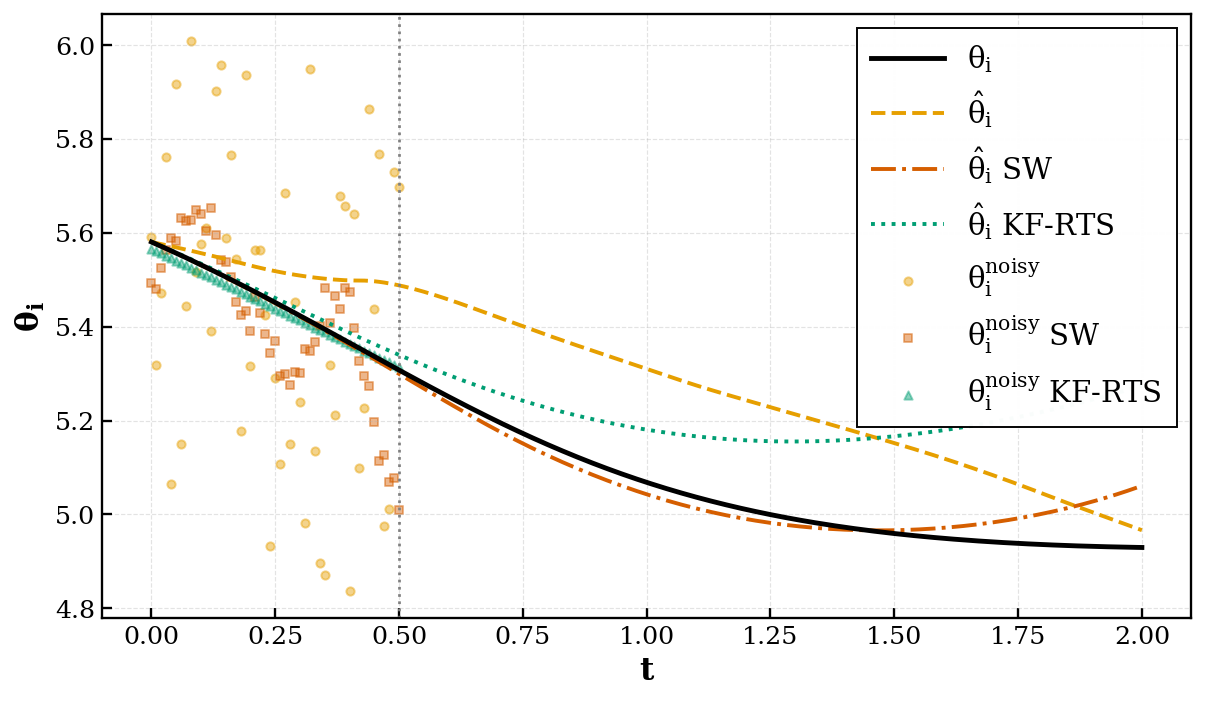

In [17]:
# Trajectory plots: one figure per noise level, all preprocessing methods in one plot

m = 0
agent_index = 0
component = 0

trajectory_paths = {}

X_true_full = train_full_clean.X[m].transpose(1, 2, 0)

for target_noise_level in TARGET_NOISE_LEVELS:
    noise_variants = make_noise_variants(target_noise_level)

    learned_by_preprocessing = {}
    noisy_fit_by_preprocessing = {}
    for preprocessing in PREPROCESSING_ORDER:
        row = df_filter[
            (np.isclose(df_filter["noise_level"], target_noise_level))
            & (df_filter["preprocessing"] == preprocessing)
        ]

        if row.empty:
            print(f"Skipping {preprocessing} at ζ={target_noise_level}: no row.")
            continue

        rollout_failed = bool(row.iloc[0].get("rollout_failed", False))
        failure_message = row.iloc[0].get("failure_message", "")

        if rollout_failed:
            print(
                f"Skipping {preprocessing} at ζ={target_noise_level}: "
                f"rollout failed. {failure_message}"
            )
            continue

        try:
            artifact = load_train_prediction_artifact(
                noise_level=target_noise_level,
                preprocessing=preprocessing,
            )
        except FileNotFoundError as e:
            print(f"Skipping {preprocessing} at ζ={target_noise_level}: missing rollout file.")
            print(e)
            continue

        learned_by_preprocessing[preprocessing] = artifact.X_hat[m].transpose(1, 2, 0)
        noisy_fit_by_preprocessing[preprocessing] = noise_variants[preprocessing].X[m].transpose(1, 2, 0)


    if D == 1:
        path = viz.plot_seen_ic_coordinate_all_preprocessing(
            t_full=train_full_clean.t,
            X_true_full=X_true_full,
            learned_by_preprocessing=learned_by_preprocessing,
            t_noisy=train_fit_clean.t,
            noisy_fit_by_preprocessing=noisy_fit_by_preprocessing,
            noise_level=target_noise_level,
            T=FIT_END_TIME,
            component=component,
            agent_index=agent_index,
            labels={
                "xlabel": r"t",
                "sys_var": r"\theta",
            },
        )
    else:
        raise NotImplementedError(
            "Use a phase-portrait all-preprocessing method for D=2 systems. "
            "This notebook cell is set up for Kuramoto D=1."
        )

    trajectory_paths[target_noise_level] = path
    print("Saved:", path)

trajectory_paths


## Compare LHS

In [21]:

from ips_learning.visualization.style import apply_paper_style, OKABE_ITO

In [22]:
fig_repo = FigureRepository(root_dir=ARTIFACTS)



PREPROCESSING_ORDER = (
    "raw",
    "sliding_window",
    "kalman_filter",
)

PREPROCESSING_COLORS = {
    "raw": OKABE_ITO[1],
    "sliding_window": OKABE_ITO[2],
    "kalman_filter": OKABE_ITO[3],
}

TRUE_COLOR = "black"

def _preprocessing_color( preprocessing: str):
        return PREPROCESSING_COLORS.get(
            preprocessing,
            OKABE_ITO[0],
        )


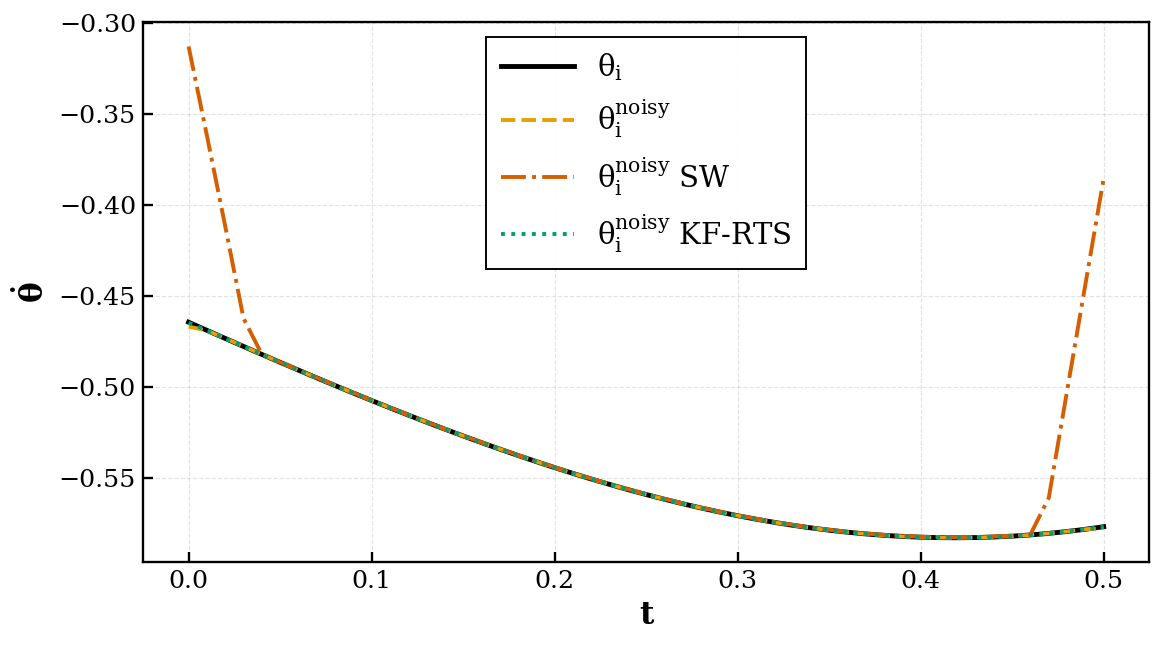

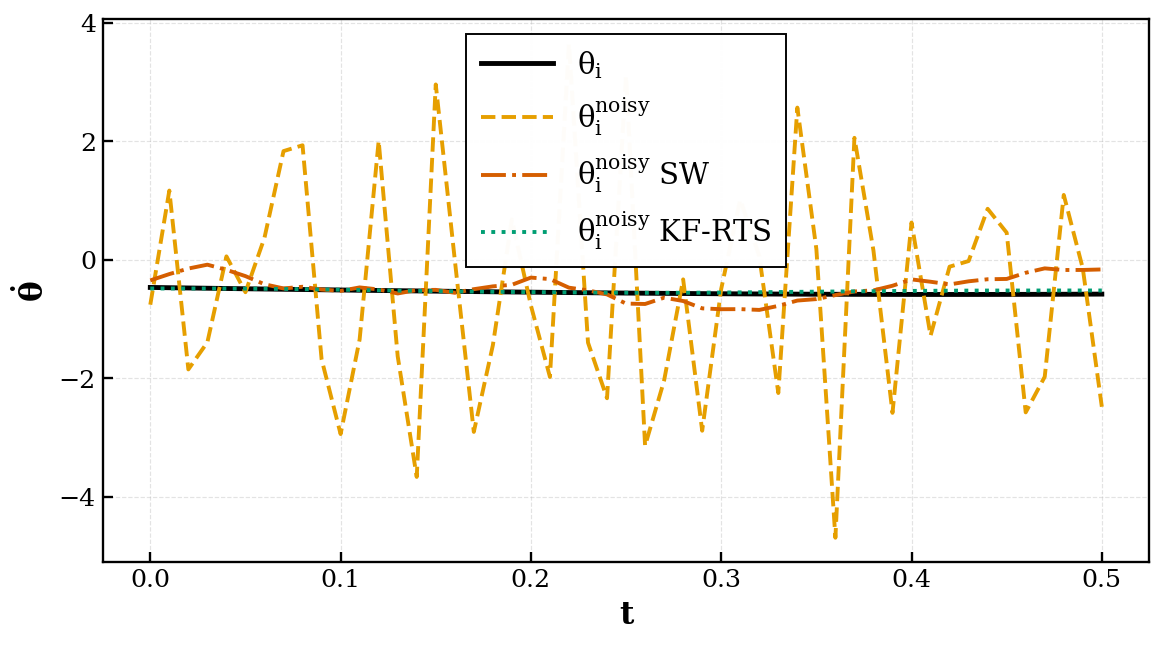

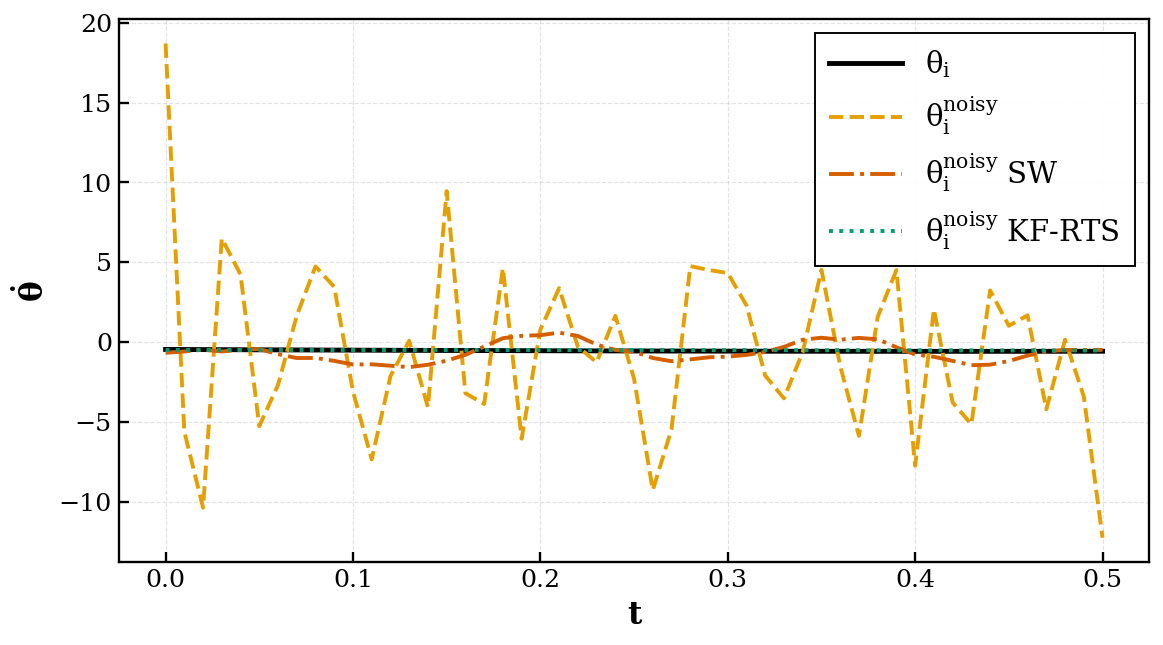

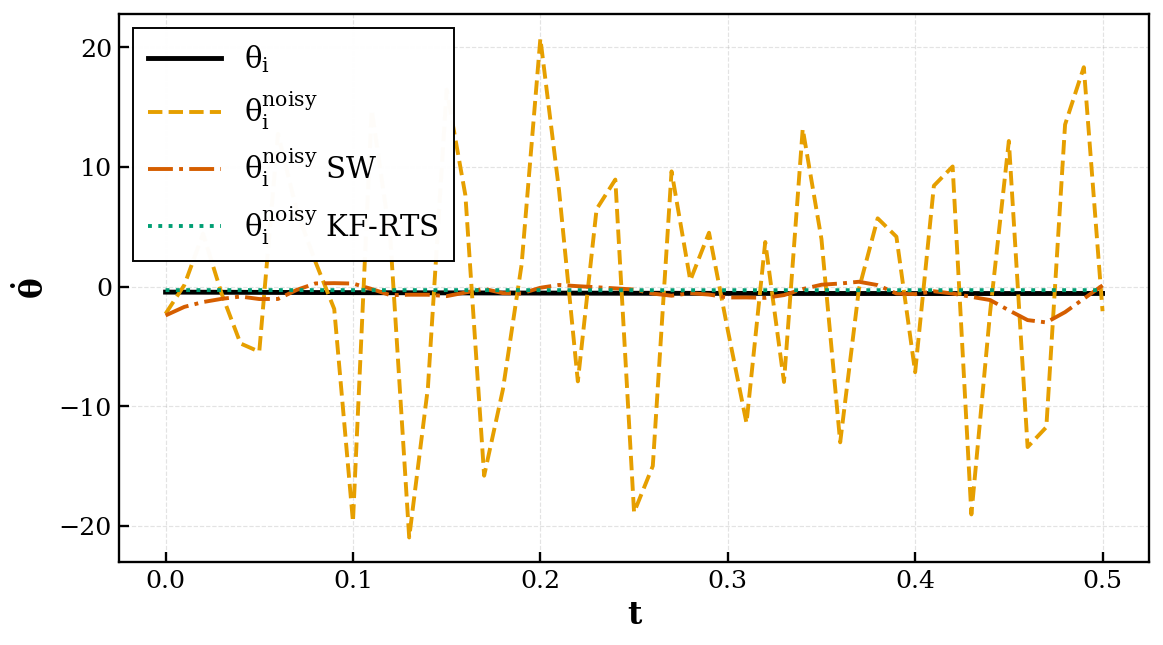

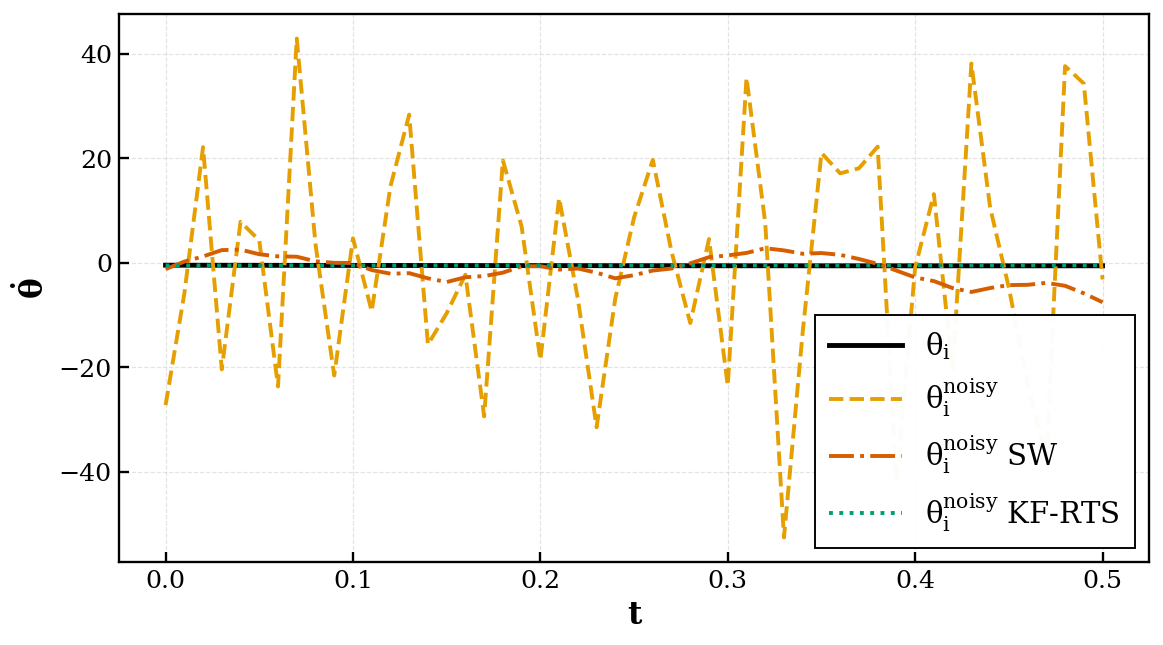

In [23]:
from ips_learning.data.dataset_repository import DatasetRepository
import matplotlib.pyplot as plt
import numpy as np

dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

PREPROCESSING_ORDER = (
    "raw",
    "sliding_window",
    "kalman_filter",
)

TARGET_NOISE_LEVELS = sorted(df_filter["noise_level"].unique())

m = 0          # trajectory
agent = 0      # agent index
component = 0  # dimension/component

for noise_level in TARGET_NOISE_LEVELS:

    fig, ax = plt.subplots(figsize=(8.5, 4.8))

    # --------------------------------------------------
    # clean reference
    # --------------------------------------------------
    clean = dataset_repo.load(
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        dataset_name=TRAIN_FIT_DATASET_NAME,
    )

    ax.plot(
        clean.t,
        clean.LHS[m, :, agent, component],
        color=TRUE_COLOR,
        linewidth=2.5,
        label=r"${\theta}_i$",
    )

    # --------------------------------------------------
    # preprocessing methods
    # --------------------------------------------------
    linestyles = {
        "raw": "--",
        "sliding_window": "-.",
        "kalman_filter": ":",
    }
    ledgend_labels = {
        "raw": "",
        "sliding_window": "SW",
        "kalman_filter": "KF-RTS",
    }

    for preprocessing in PREPROCESSING_ORDER:

        case_name = noise_filter_case_name(
            noise_level,
            preprocessing,
        )

        try:
            dataset = dataset_repo.load(
                system_name=SYSTEM_NAME,
                profile_name=PROFILE_NAME,
                split="noise_filter_sweep",
                dataset_name=case_name,
            )
        except FileNotFoundError:
            print(f"Missing dataset: {case_name}")
            continue

        ax.plot(
            dataset.t,
            dataset.LHS[m, :, agent, component],
            linestyle=linestyles.get(preprocessing, "--"),
            linewidth=2,
            color=_preprocessing_color(preprocessing),
            label=(rf"${{\theta}}^{{noisy}}_{{i}}$"+ f" {ledgend_labels.get(preprocessing, preprocessing)}"),
        )

    # ax.set_title(
    #     rf"$\dot{{\theta}}_{{i={agent+1}}}$"
    # )

    if SYSTEM_NAME == "kuramoto":
        ax.set_ylabel(r"$\dot{\theta}$")
    else:
        ax.set_ylabel(r"$\dot{\theta}$")

    ax.set_xlabel("t")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend()

    plt.tight_layout()
    plt.show()

    fig_repo.save(
            fig,
            system_name=SYSTEM_NAME,
            stage_name=FIGURE_STAGE,
            file_name=f"noise_filter_sweep_trajectory_LHS_agent{agent+1}_noise{str(noise_level).replace('.', 'p')}",
            close=False,
        )

# Compare X

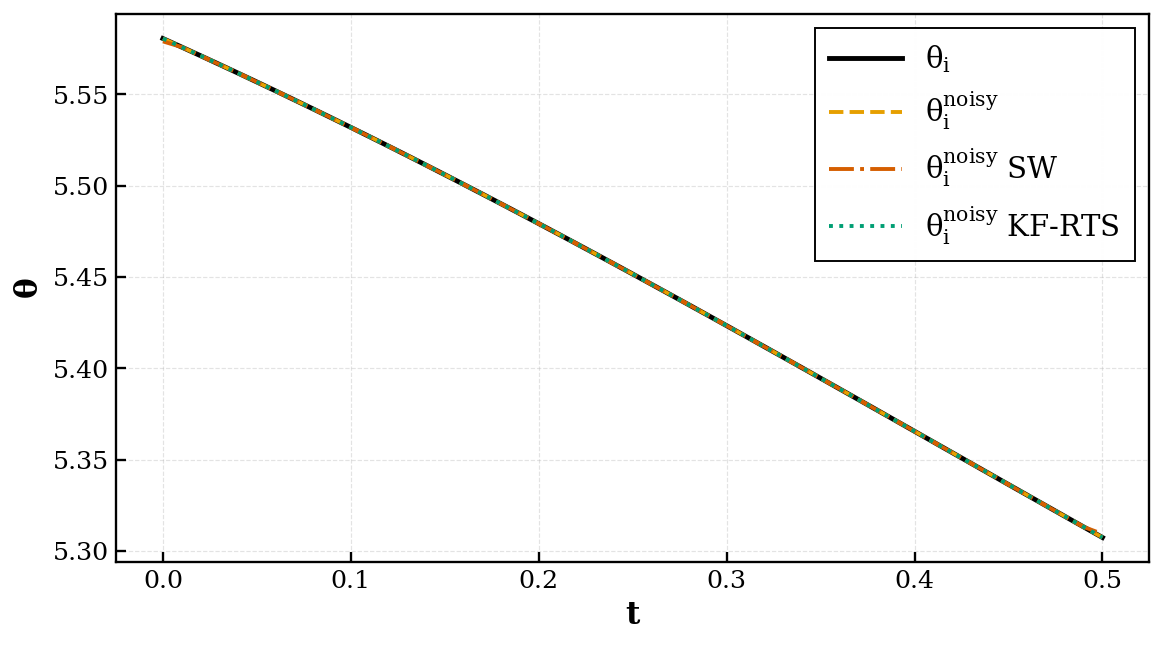

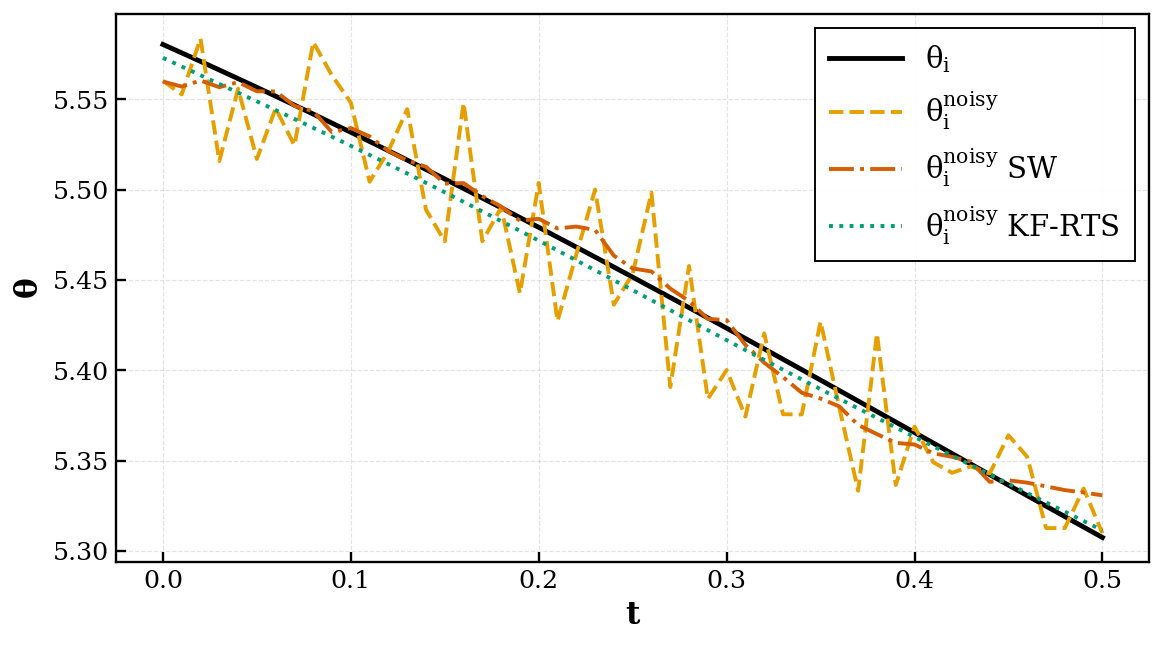

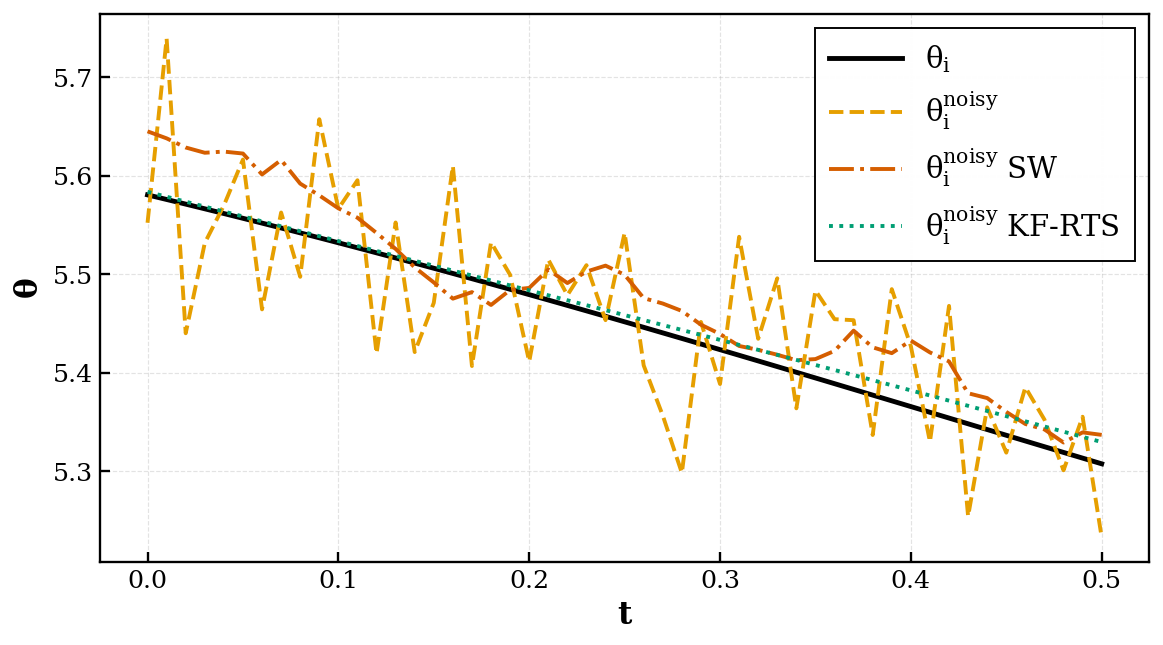

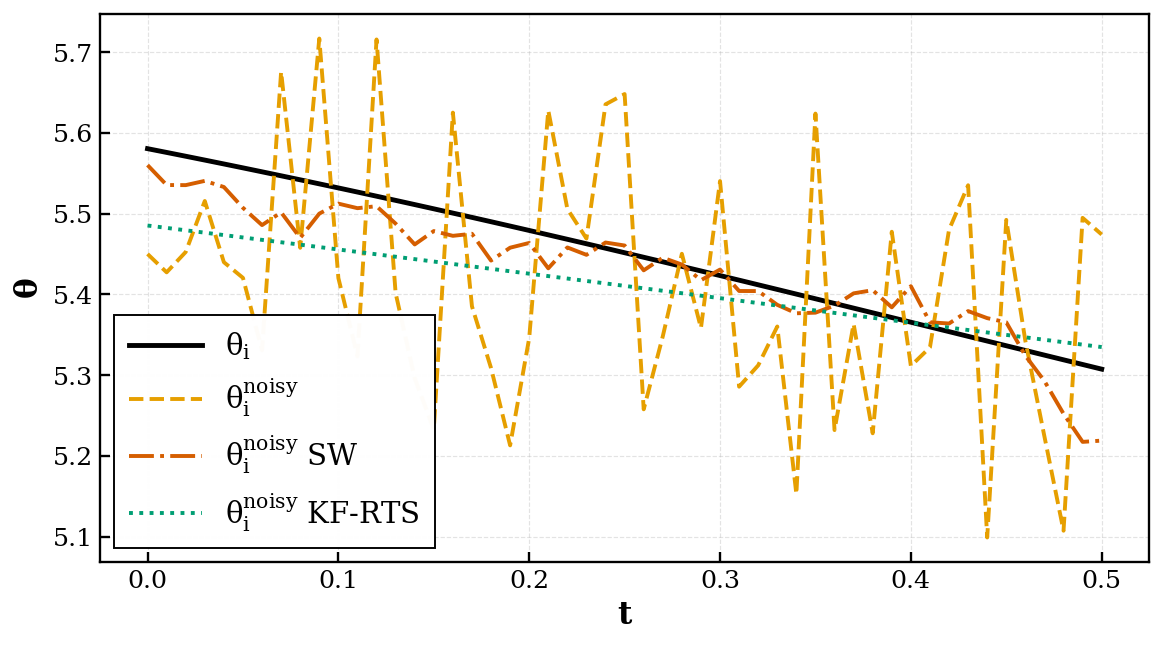

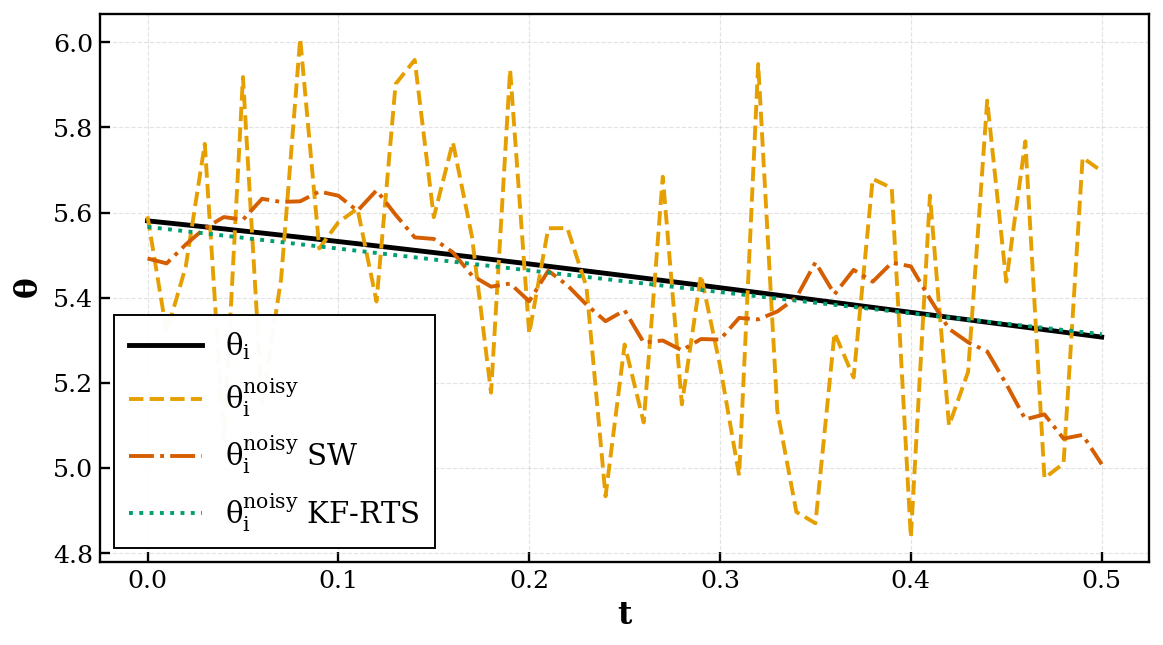

In [24]:
from ips_learning.data.dataset_repository import DatasetRepository
import matplotlib.pyplot as plt
import numpy as np


dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

PREPROCESSING_ORDER = (
    "raw",
    "sliding_window",
    "kalman_filter",
)

TARGET_NOISE_LEVELS = sorted(df_filter["noise_level"].unique())

m = 0          # trajectory
agent = 0      # agent index
component = 0  # dimension/component

for noise_level in TARGET_NOISE_LEVELS:

    fig, ax = plt.subplots(figsize=(8.5, 4.8))

    # --------------------------------------------------
    # clean reference
    # --------------------------------------------------
    clean = dataset_repo.load(
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        dataset_name=TRAIN_FIT_DATASET_NAME,
    )

    ax.plot(
        clean.t,
        clean.X[m, :, agent, component],
        color=TRUE_COLOR,
        linewidth=2.5,
        label=r"${\theta}_i$",
    )

    # --------------------------------------------------
    # preprocessing methods
    # --------------------------------------------------
    linestyles = {
        "raw": "--",
        "sliding_window": "-.",
        "kalman_filter": ":",
    }
    ledgend_labels = {
        "raw": "",
        "sliding_window": "SW",
        "kalman_filter": "KF-RTS",
    }

    for preprocessing in PREPROCESSING_ORDER:

        case_name = noise_filter_case_name(
            noise_level,
            preprocessing,
        )

        try:
            dataset = dataset_repo.load(
                system_name=SYSTEM_NAME,
                profile_name=PROFILE_NAME,
                split="noise_filter_sweep",
                dataset_name=case_name,
            )
        except FileNotFoundError:
            print(f"Missing dataset: {case_name}")
            continue

        ax.plot(
            dataset.t,
            dataset.X[m, :, agent, component],
            linestyle=linestyles.get(preprocessing, "--"),
            color=_preprocessing_color(preprocessing),
            linewidth=2,
            label=(rf"${{\theta}}^{{noisy}}_{{i}}$"+ f" {ledgend_labels.get(preprocessing, preprocessing)}"),
        )

    # ax.set_title(
    #     rf"$\zeta={noise_level}$ :$(\theta_{{i={agent+1}}})$"
    # )

    if SYSTEM_NAME == "kuramoto":
        ax.set_ylabel(r"$\theta$")
    else:
        ax.set_ylabel("X")

    ax.set_xlabel("t")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend()

    plt.tight_layout()
    plt.show()
    fig_repo.save(
            fig,
            system_name=SYSTEM_NAME,
            stage_name=FIGURE_STAGE,
            file_name=f"noise_filter_sweep_trajectory_X_agent{agent+1}_noise{str(noise_level).replace('.', 'p')}",
            close=False,
        )